# EdgeAI

The intersection of **embedded systems** and **machine learning** is opening the door to an entirely new generation of applications that are far more **responsive**, **interactive**, and **context-aware**. By moving inference directly onto low-power devices, it becomes possible to build systems capable of **always-on machine learning**, continuously sensing and reacting to the environment **without relying on a remote server**. A familiar example is the wake-word detection used by voice assistants such as "OK Google", "Alexa", or "Hey Siri". In this scenario, a machine learning model runs locally on the device and continuously listens for a specific keyword. The process begins with the acquisition of the audio signal through microphones. The incoming sound is then processed on-device to determine whether the spoken phrase actually corresponds to the target wake word. If the keyword is detected, the system activates and typically provides immediate feedback, for example by lighting LEDs, playing a sound, or waking the main processor. This simple example captures the essence of embedded intelligence: a system receives data from the physical world, processes it locally using machine learning algorithms, and produces an action or response. In other words, every embedded AI application follows the same fundamental pipeline:

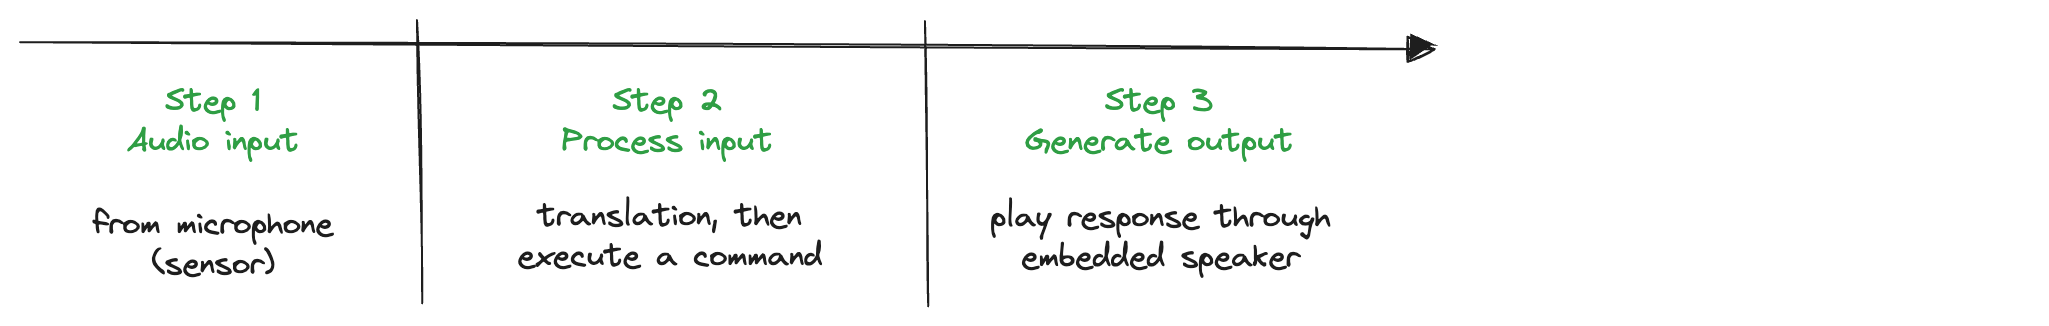

The key challenge is understanding how to shrink and compress models while preserving their ability to recognize meaningful patterns in data. This is one of the central problems in Edge AI:: reducing computational and memory requirements without significantly degrading predictive performance. A crucial observation is that the most computationally expensive phase of machine learning is typically the **training process**, where the model learns patterns from large datasets. Training requires massive computational resources, large memory capacities, and often specialized hardware accelerators available in datacenters or cloud infrastructures. Once the learning phase is complete, however, the resulting model can be deployed to an embedded device, where it is only used to perform **inference**, namely applying the learned patterns to new incoming data. The distinction between training and inference is fundamental. "Learning how to perform a task" is dramatically more demanding than simply "executing what has already been learned". This asymmetry is precisely what makes EdgeAI feasible: we can exploit powerful servers and GPUs for training, while reserving the lightweight inference stage for the embedded device. During training, developers typically rely on high-level machine learning frameworks such as PyTorch or Keras, which provide flexible tools for defining, training, and evaluating neural networks.  On embedded devices, however, such heavyweight frameworks are impractical. Once trained, the model undergoes a **conversion and optimization phase**, where techniques such as **quantization**, **pruning**, and **compression** are applied to reduce its size and computational cost. Finally, the optimized model is **deployed** onto the embedded target, where the model is executed locally on the limited hardware resources of the device.

# Embedded System

The input stage is fundamentally tied to **sensors**, since these systems interact directly with the physical world. In the case of a voice assistant, for example, the primary input comes from an acoustic sensor: the microphone, which captures the incoming sound waves and converts them into a digital signal that can be processed by the machine learning model. However, the is a wide variety of sensors that can be used, including:

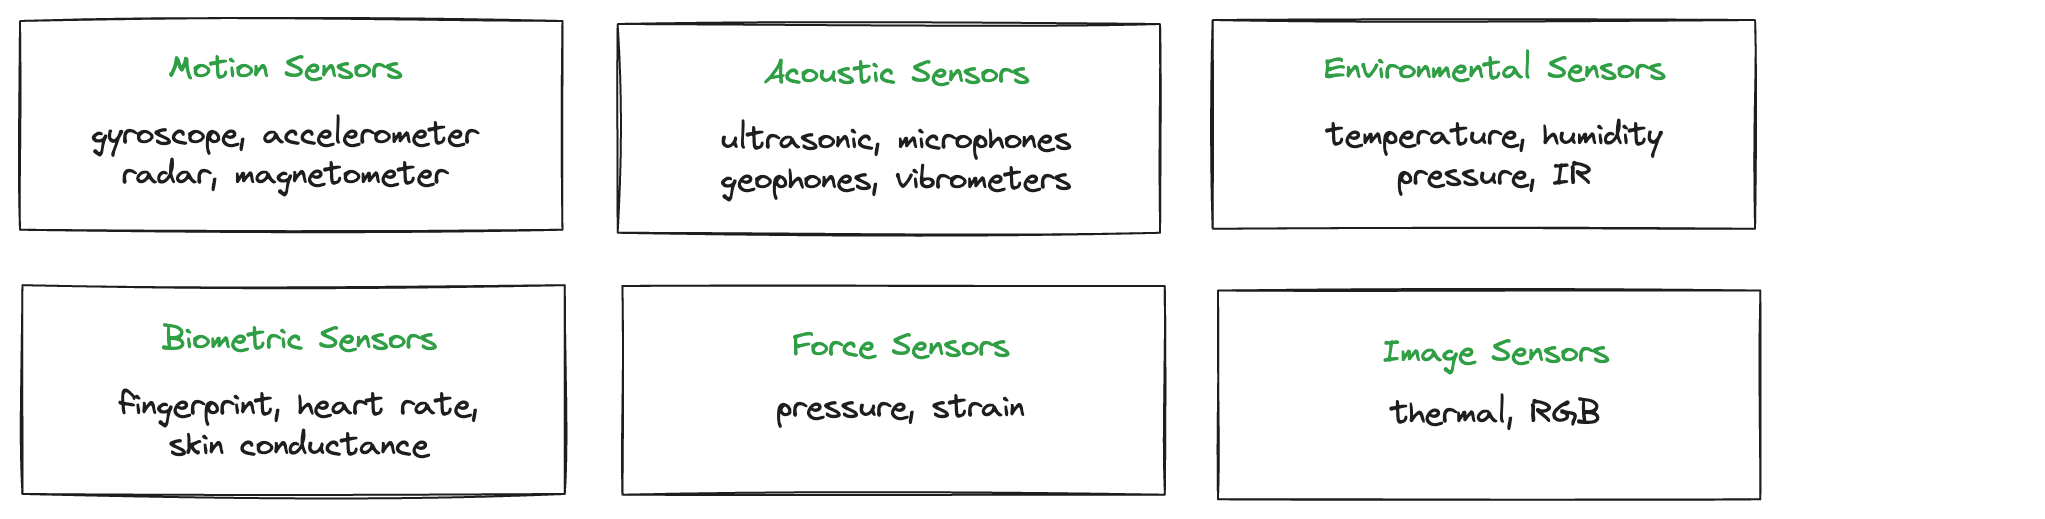

The input is then processed locally by an **emdedded system**. This processing stage is the most challenging aspect of EdgeAI, because the machine learning model must operate under **severe resource constraints**, including limited memory, computational power, and energy consumption. Unlike cloud-based systems, these devices must perform inference efficiently and often in real time, while consuming only a few milliwatts of power. Finally, the system produces an output, namely the feedback or action generated in response to the processed input. In the case of a voice assistant, this output might consist of an LED turning on, a sound being played through a speaker, or a message appearing on a display. More generally, embedded systems can interact with the environment through a variety of **actuators**, including physical devices such as motors and servos, or digital interfaces such as screens and communication modules.

### Hardware perspective

An embedded system shares many similarities with a conventional computer: it still contains a processor, memory, and storage However, what fundamentally distinguishes it is the way these components are integrated and organized, not simply their physical size. In a typical **computer system**, the **microprocessor** is only one element within a much larger architecture: 

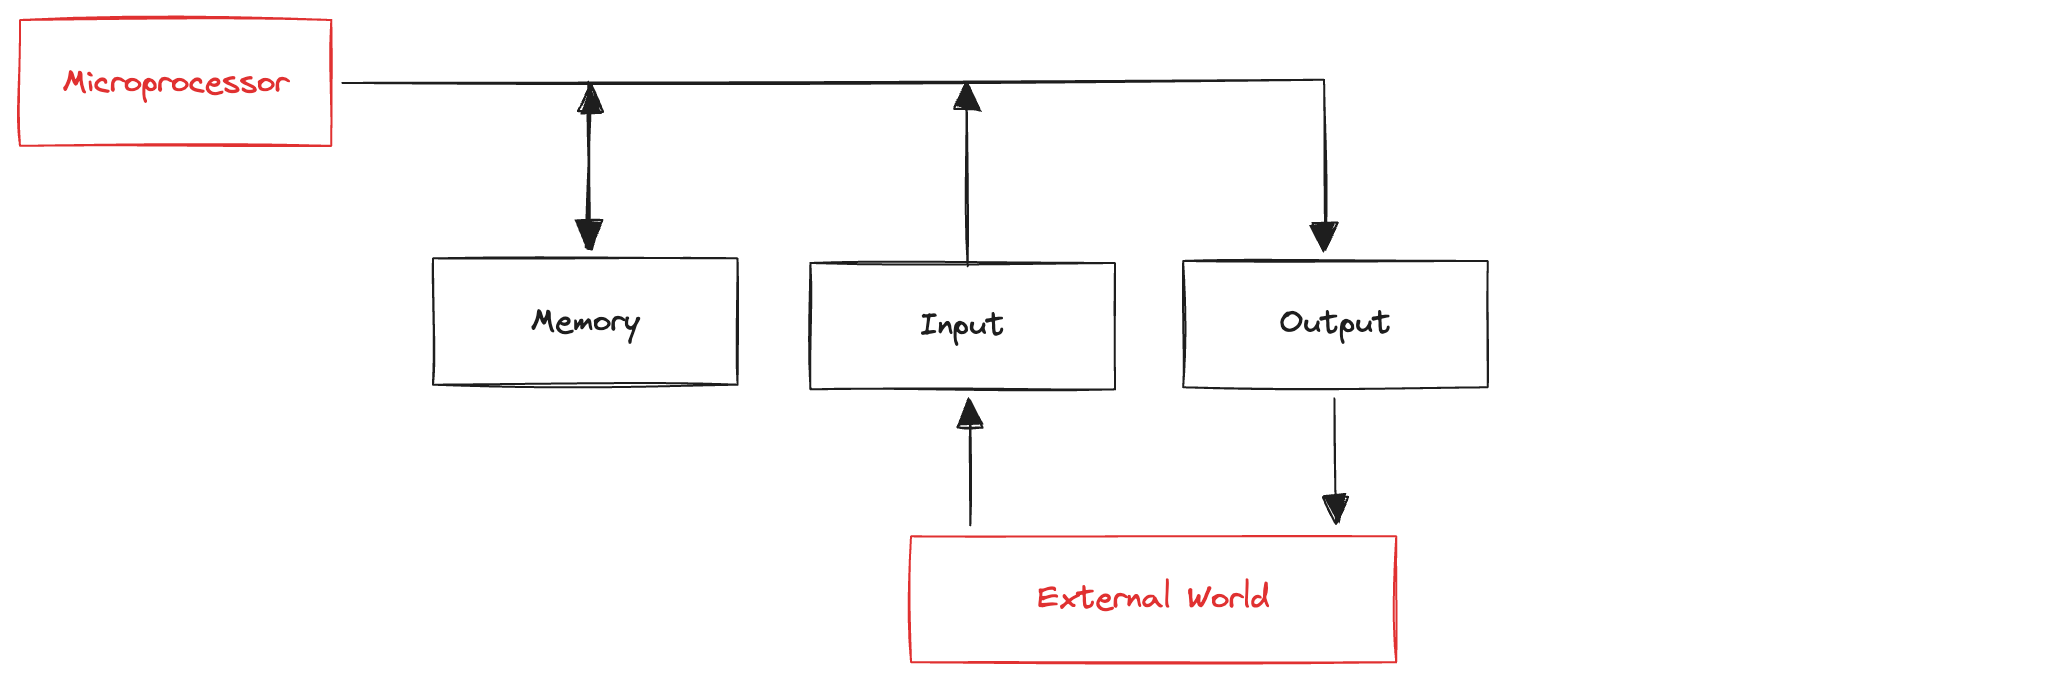

It communicates with external RAM, storage devices, graphics units, and peripheral controllers through complex buses and interfaces. These systems are designed for **general-purpose computing**, such as laptops, desktops, and servers, where the hardware configuration can be customized depending on the application requirements.

An **embedded system** follows a very different philosophy. Instead of relying on many external components, the processor, memory, and storage are all integrated into a single **microcontroller** chip:

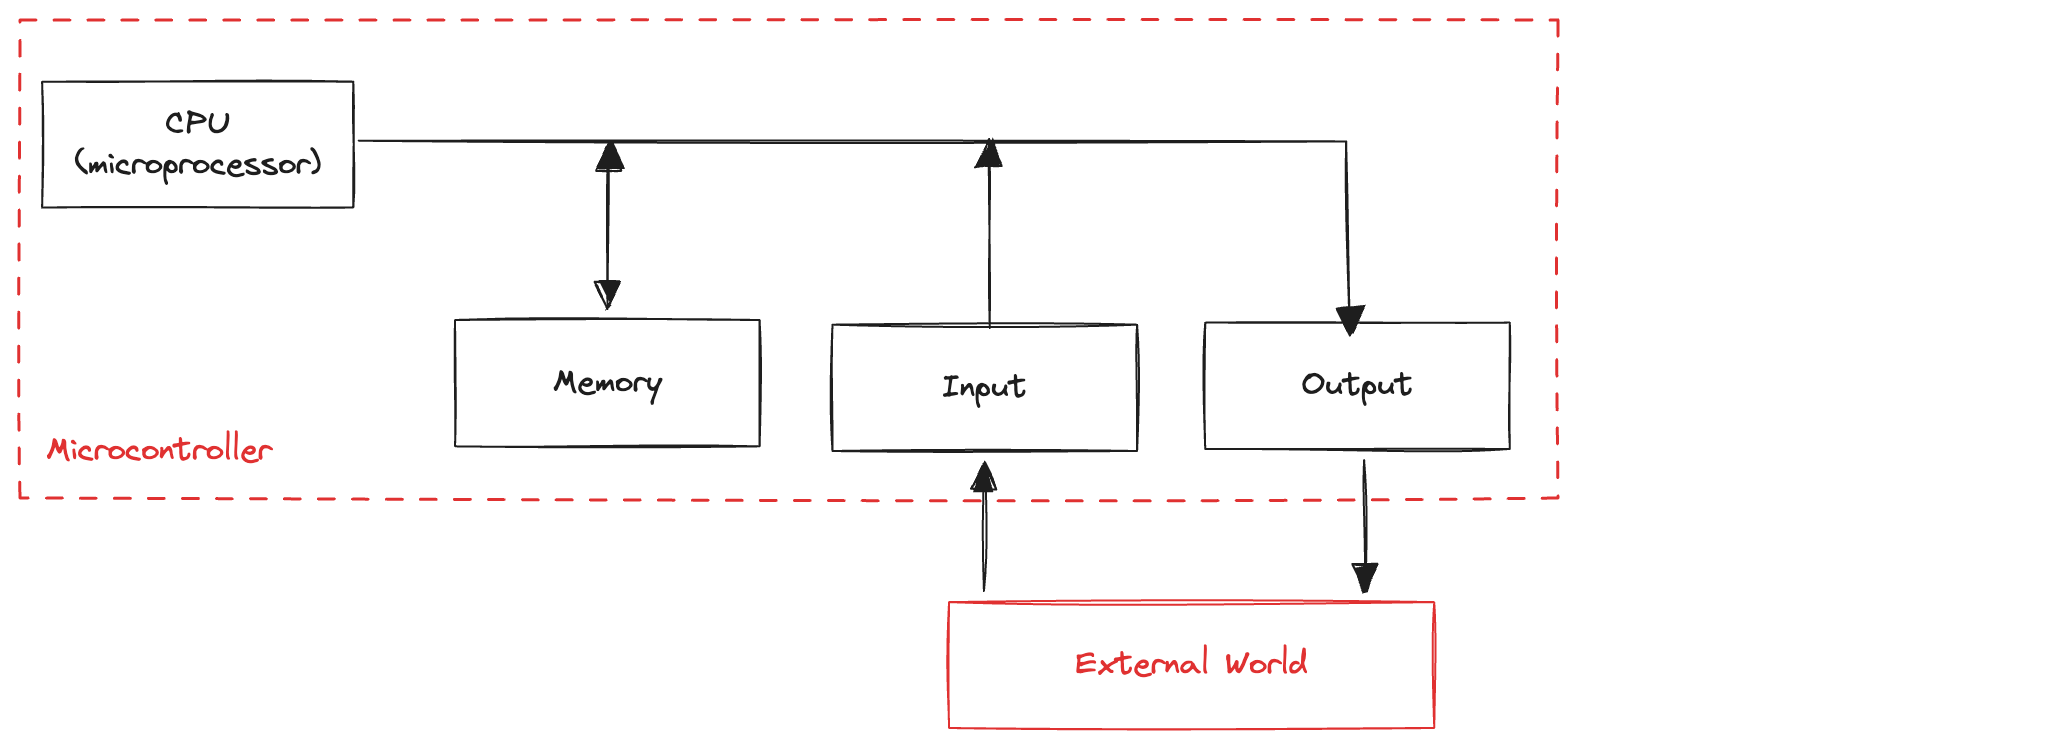

Everything is already tightly coupled and optimized for compactness, low power consumption, and real-time operation. Microcontrollers are therefore typically designed for **specific and dedicated tasks**, such as controlling an MP3 player, managing a washing machine, handling sensor acquisition, or responding to user interactions in embedded devices. Rather than supporting arbitrary workloads, they are usually built around a predefined functionality. This distinction is especially evident in terms of computing power, available memory, storage capacity, and power consumption. While general-purpose processors prioritize performance and versatility, microcontrollers are engineered to operate efficiently with minimal resources, making them ideal for battery-powered, low-cost, and always-on embedded applications.

### Software perspective

Embedded system design also introduces several challenges on the software side. In general, **software stacks** are organized into three abstraction layers: the high-level application layer, a set of libraries that support the application, and the operating system, which provides the low-level services required by both libraries and applications. The major difference with respect to conventional computing systems appears at the operating system level. On desktops, laptops, servers, and smartphones, operating systems such as Windows, Linux, macOS, Android, or iOS provide **a rich and flexible execution environment**. Developers can rely on a large ecosystem of services, drivers, and APIs to build a wide variety of applications without needing to manage the underlying hardware directly. Embedded systems, however, are usually designed for highly specialized and dedicated tasks, and therefore they often **do not include a full-featured operating system**. Lightweight embedded operating systems such as FreeRTOS or Arm Mbed OS do exist, but many embedded applications run directly **on bare metal** without an OS at all. The reason is simple: every additional software layer consumes memory, storage, and processing resources, which are already extremely limited in embedded platforms. Minimizing software overhead is therefore essential to maximize efficiency and responsiveness.

A similar issue arises at the **library level**. In conventional computing environments, software libraries such as NumPy are almost universally available and behave consistently across different hardware platforms. Once an application is written, developers can generally execute it on different systems without worrying about the underlying processor architecture. The library provides a convenient abstraction layer that hides low-level implementation details and guarantees portability. In embedded systems, this level of uniformity is much harder to achieve. Hardware architectures, memory layouts, accelerators, and instruction sets can **vary significantly from one platform to another**. As a consequence, developers often face a fundamental **trade-off between portability and efficiency**. Highly portable code may not fully exploit the hardware capabilities of a specific device, while highly optimized implementations are frequently platform-dependent.

### Model perspective

How can machine learning and embedded systems be combined? At first glance, the two worlds seem **fundamentally incompatible**. On one side, modern machine learning models are becoming larger and more computationally demanding every year. On the other side, embedded devices are extremely resource constrained, often characterized by limited memory, low computational power, strict energy budgets, and minimal software support. The challenge is therefore clear: how can we deploy increasingly sophisticated machine learning models onto tiny edge devices? The answer lies in **the nature of the data** itself. Although modern datacenters and cloud infrastructures provide enormous computational capabilities, they are only able to process a small fraction of the data continuously generated by the physical world. Sensors embedded in smartphones, wearables, industrial systems, vehicles, and IoT devices produce **massive streams of information at the edge of the network**. Transmitting all of this raw data to the cloud is often impractical because of **bandwidth limitations**, **latency constraints**, **privacy concerns**, and **energy costs**. For this reason, models are increasingly moving toward a different paradigm: instead of moving the data to the computation, we **move the computation to the data**. This is the key motivation behind Edge AI. By running machine learning models directly on the device where data is generated, we can achieve low latency, reduced communication costs, improved privacy, and always-on intelligence. The evolution of deep learning architectures clearly reflects this tension between accuracy and computational efficiency. A useful example is shown in the benchmark study [Benchmark Analysis of Representative Deep Neural Network Architectures](./papers/(2018)%20-%20Benchmark%20Analysis%20of%20Representative%20Deep%20Neural%20Network%20Architectures.pdf), where neural network models are compared in terms of accuracy, computational complexity, and model size. The chart highlights how achieving higher accuracy has historically required increasingly larger and more computationally expensive models:

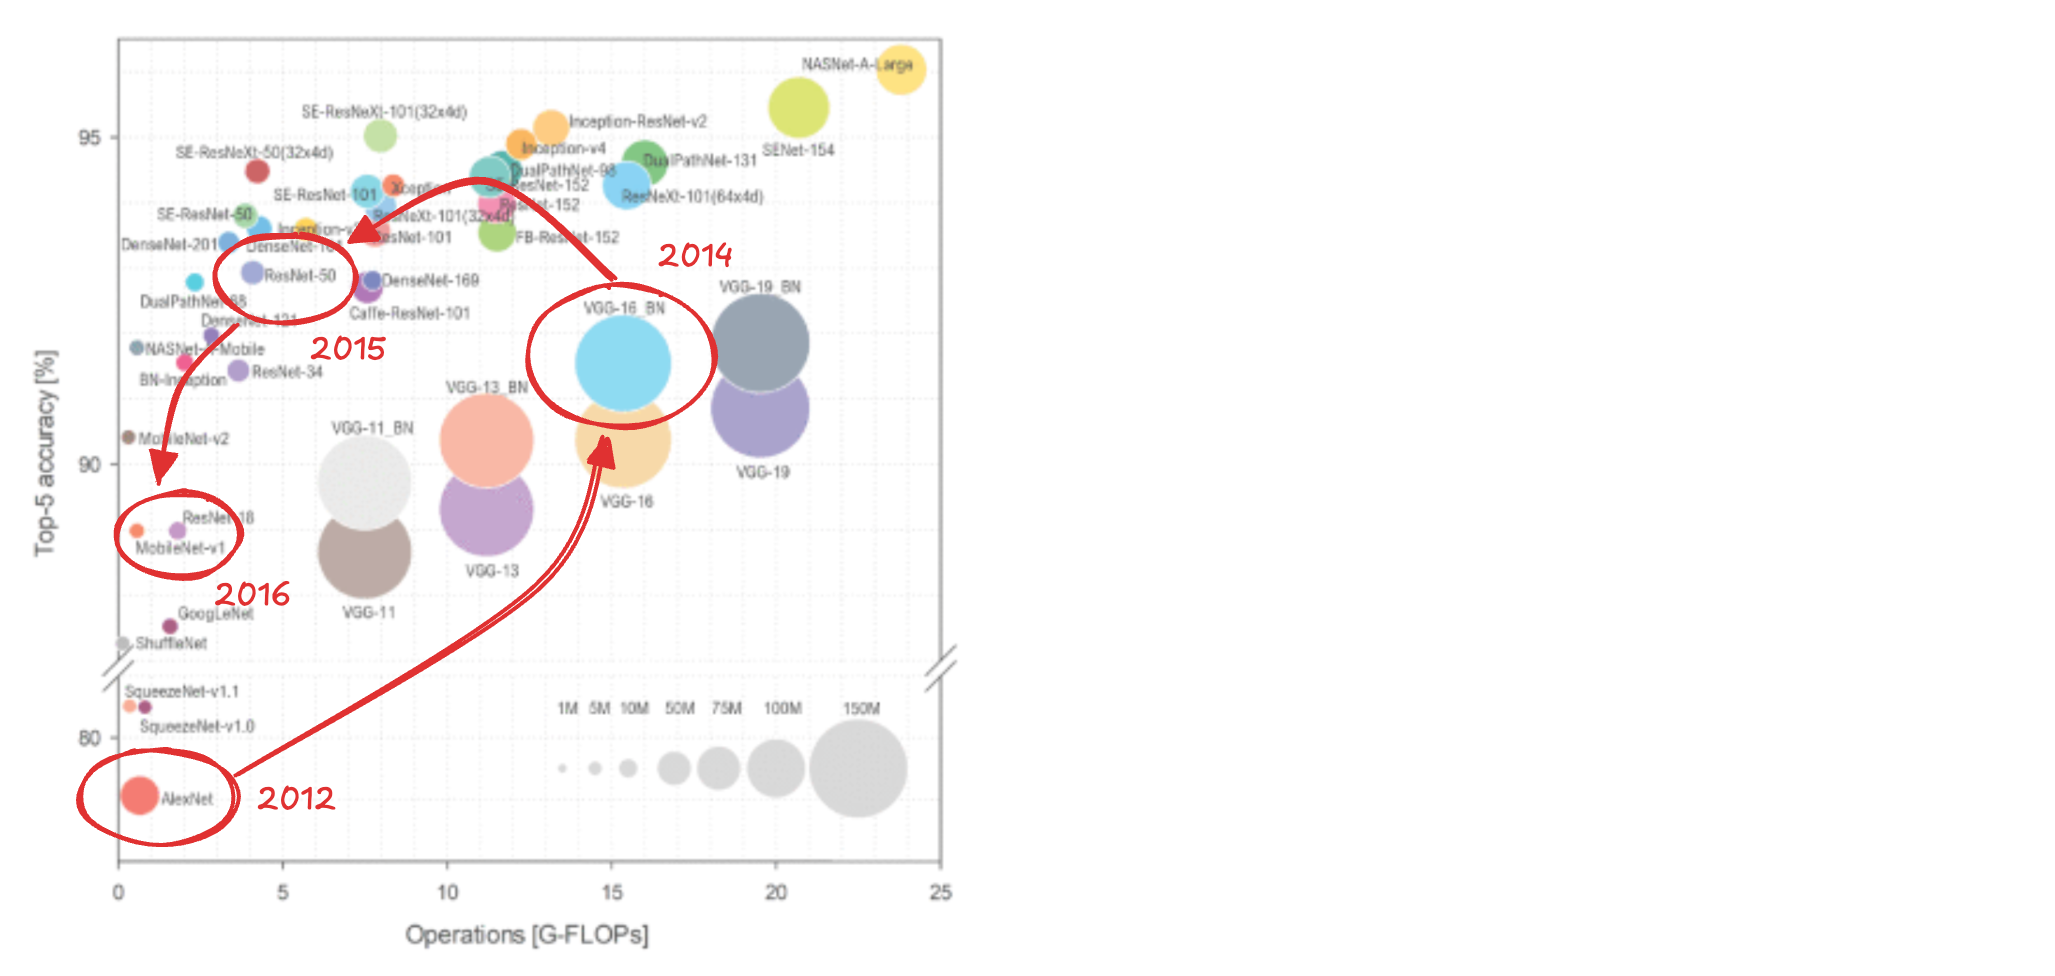

Early architectures such as AlexNet demonstrated the power of deep learning by achieving impressive image classification performance on ImageNet, but they already required relatively large models. Subsequent architectures such as VGGNet further improved accuracy, although at the cost of a dramatic increase in memory and computation requirements. At that point, it became evident that simply scaling models indefinitely was not a sustainable strategy. This realization led to the development of **more efficient architectures**. Networks such as ResNet showed that it was possible to improve accuracy while simultaneously reducing some of the computational burden through better architectural design. Later, with the widespread adoption of smartphones and mobile AI applications, efficiency became a primary objective. Architectures such as MobileNet were explicitly designed for resource-constrained platforms, sacrificing a small amount of accuracy in exchange for drastic reductions in model size and computational cost. Since then, many additional **efficient architectures** have been proposed, but the underlying lesson remains the same: **machine learning models must be designed with hardware constraints in mind**.



## Quantization

When neural networks were first developed, the primary challenge was simply making them work reliably. As a result, the main focus was on achieving high accuracy and reducing training time. In this context, **floating-point arithmetic** naturally became the preferred choice: it preserves numerical precision well, and GPUs were already highly optimized for accelerating floating-point operations. Consequently, little attention was initially given to **alternative numerical representations**. Floating-point numbers are extremely flexible because they can represent values spanning a **very large dynamic range**, from extremely small to extremely large magnitudes, while still maintaining **good precision**. In this sense, they behave similarly to scientific notation:

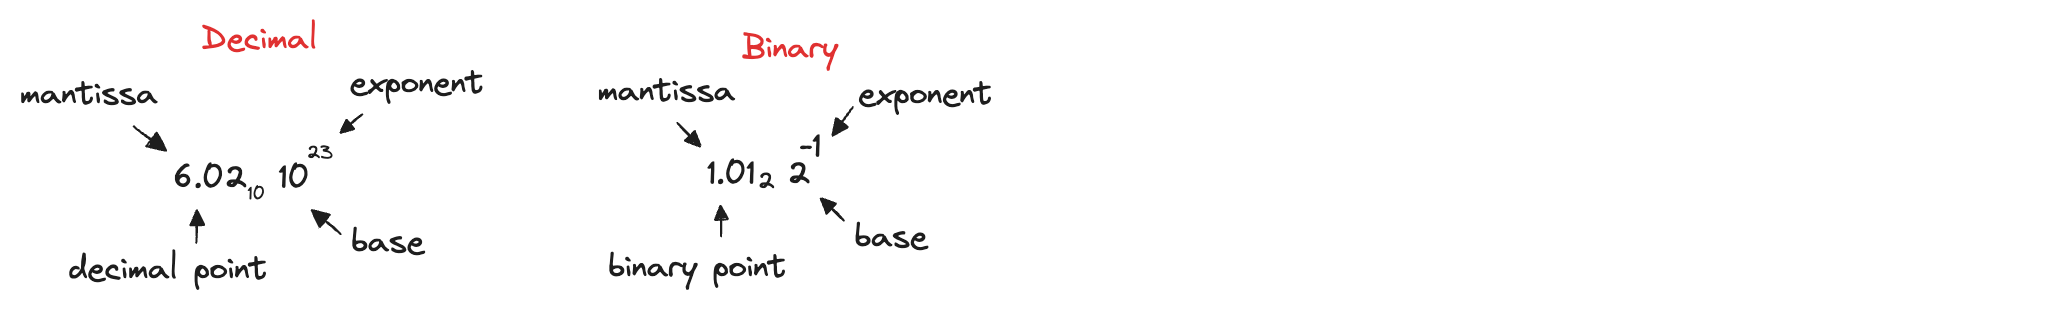

The **IEEE 754 standard** defines the most widely adopted floating-point representations used in modern computer systems, including formats such as 32-bit single precision (FP32) and 64-bit double precision (FP64):

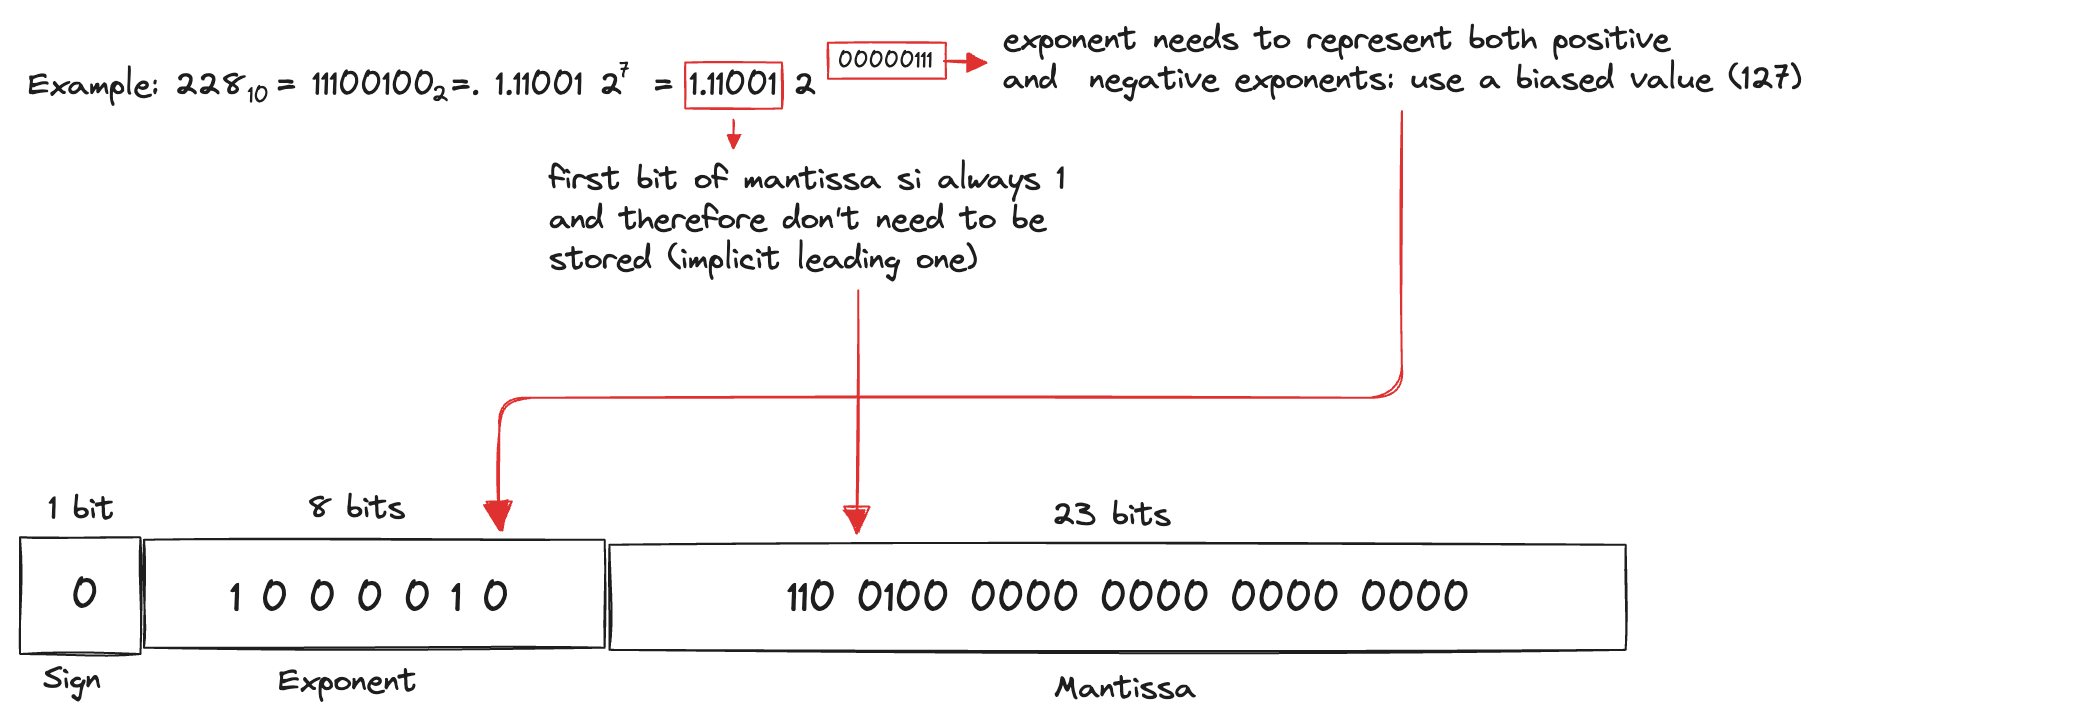

Floating-point arithmetic is particularly important in neural network **training** because optimization algorithms such as stochastic gradient descent update the weights through a large number of very small incremental changes. These updates often involve extremely small values that require sufficient numerical precision to be represented correctly. If the numerical format cannot accurately represent such small gradients, they may effectively become zero during computation, contributing to phenomena such as the **vanishing gradient problem**, where learning slows down or completely stops in deep networks.

The requirements of **inference** are very different from those of training. Once a model is deployed, the computational workload grows with the number of users and requests, and unlike training, which happens once on powerful hardware, inference must happen continuously, often on constrained devices or at massive scale. This makes efficiency a real concern: every millisecond of latency and every milliwatt of power consumption matters. This is where [**quantization**](./papers/(2017)%20-%20Quantization%20and%20Training%20of%20Neural%20Networks%20for%20Efficient%20Integer-Arithmetic-Only%20Inference.pdf) comes in. The idea is simple: instead of storing and computing with full-precision floating-point numbers, we use **more compact formats**. As concrete example, taking a 32-bit float (4 bytes) and mapping it to an 8-bit integer (1 byte) immediately gives us a 4x reduction in memory footprint, with potential speedups in computation as well.

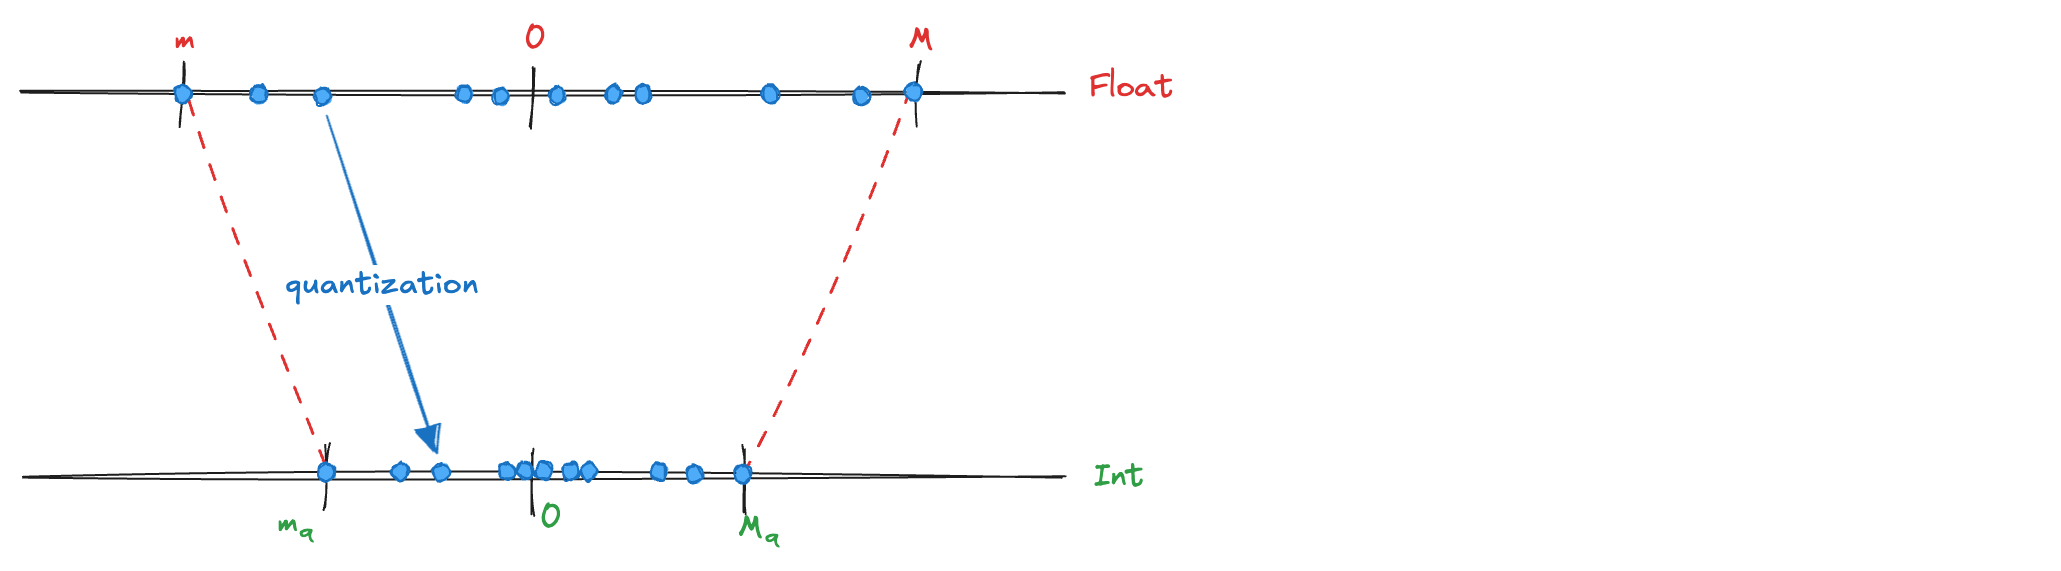

Mathematically, we want to map a floating-point value:

$\displaystyle x \in [m, M]$ 

to a b-bit integer:

$\displaystyle x_q \in [m_q, M_q]$ 

We do this through a **linear transformation** controlled by two parameters, the **scale factor** and the **zero-point**:

$\displaystyle x_q = \text{round}\!\left(\frac{x}{s} + z\right)$

In practice, some values may fall outside the range, for instance due to outliers, so we add a clipping step to keep the quantized value within the valid integer range:

$\displaystyle x_q = \text{clip}\!\left(\text{round}\!\left(\frac{x}{s} + z\right), m_q, M_q\right)$

In [3]:
import numpy as np

def quantization(x, s, z, min_q, max_q):

    # Quantize the input data x using the scale s and zero point z, 
    # we use floor to round down the quantized values, and then
    # we add 0.5 to implement rounding to the nearest integer
    x_q = np.floor(x / s + z + 0.5)

    # Clip the quantized values to be within the range of [min_q, max_q]
    x_q = np.clip(x_q, a_min=min_q, a_max=max_q)

    # Convert the quantized values to int8 data type and return
    return x_q.astype(np.uint8) if min_q == 0 else x_q.astype(np.int8)

The inverse operation of **de-quantization** simply reverses the mapping:

$\displaystyle x = s\,(x_q - z)$

In [4]:
def dequantization(x_q, s, z):

    # Dequantize the quantized values x_q using the scale s and zero point z
    x_d = s * (x_q - z)

    # Convert the dequantized values to float32 data type and return
    return x_d.astype(np.float32)

The scale and zero-point are chosen so that the endpoints of the floating-point range map exactly to the endpoints of the integer range, which gives us a simple linear system to solve:

$\displaystyle m = s\,(m_q - z)$

$\displaystyle M = s\,(M_q - z)$

Solving for the two unknowns:

$\displaystyle s = \frac{M - m}{M_q - m_q}$

$\displaystyle z = \frac{m M_q - M m_q}{m - M}$

The selectoin of integer range depends on the number of bits we want to use for the quantization and the signedness of the integer type:

- For **signed INT b** the range is $(-2^{b-1},\, 2^{b-1}-1)$
- For **unsigned UINT b** it is $(0,\, 2^b-1)$

In [5]:
def generate_quantization_parameters(min, max, bits=8, signed=True):
    
    # Define the quantized range based on the number of bits and signedness
    if signed:
        min_q = -2 ** (bits - 1)
        max_q =  2 ** (bits - 1) - 1
    else:
        min_q = 0
        max_q = 2 ** bits - 1
    
    # Calculate the scale
    s = (max - min) / (max_q - min_q)

    # Calculate the zero point
    z = (max_q * min - max * min_q) / (min - max)

    # Return the quantization parameters
    return s, z, min_q, max_q

Note that in this implementation the bits parameter controls the range of the quantized values, but not their actual storage type. The python code can be used only for some type of integer (e.g., int8), but the same mathematical principles apply to any quantization scheme, including formats such as 4-bit integers. 

As an example, suppose to have floating point values ranging from -6 to 5 and an 4 bit signed conversion:

In [6]:
min = -6
max = 5

s, z, min_q, max_q = generate_quantization_parameters(min, max)

print(f"Scale: {s}")
print(f"Zero Point: {z}")
print(f"Quantized Range: [{min_q}, {max_q}]")

Scale: 0.043137254901960784
Zero Point: 11.090909090909092
Quantized Range: [-128, 127]


We can quantize and then de-quantize some values:

In [7]:
x = -5.4

x_q = quantization(x, s, z, min_q, max_q)
x_d = dequantization(x_q, s, z)

print("x = ", x)
print("x_q = ", x_q)
print("x_d = ", x_d)

x =  -5.4
x_q =  -114
x_d =  -5.3960786


The reconstructed value is close to the original one but not identical, the small difference is the **quantization error**, an unavoidable consequence of mapping a continuous value onto a discrete grid. To better understand this phenomenon, we can plot the quantization value as a function of the floating point value:

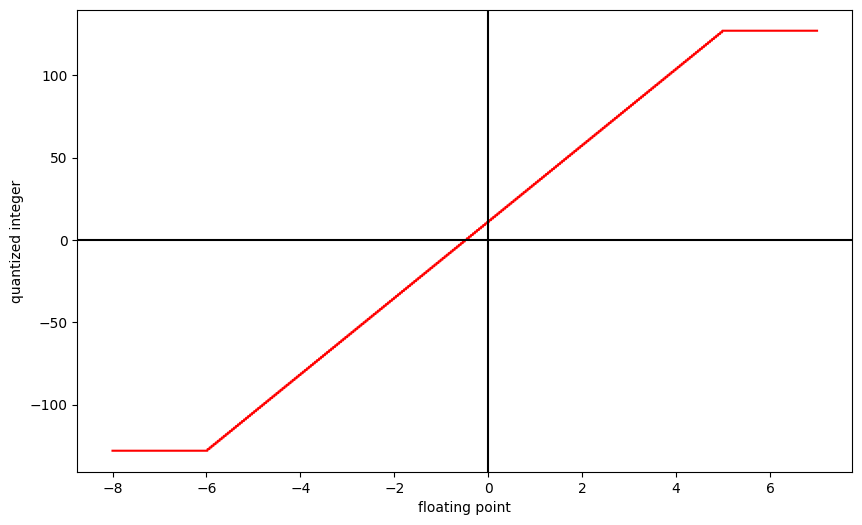

In [8]:
import matplotlib.pyplot as plt

# Generate a range of floating point values around the original range
x = np.arange (min-2, max+2, 0.001)

# Quantize the floating point values using the quantization function
x_q = quantization(x, s, z, min_q, max_q)

# Plot the quantized values against the original floating point values
plt.figure(figsize=(10, 6))
plt.plot(x, x_q, 'r')
plt.ylabel('quantized integer')
plt.xlabel('floating point')
plt.axhline(y=0, color='k')
plt.axvline(x=0, color='k')
plt.show()

The linear region in the middle is where the mapping is active: each floating-point value gets assigned a unique integer. The flat regions at both ends are the effect of clipping: values that fall outside the range all collapse to the same integer boundary, losing any distinction between them. However, if we zoom in to the linear region:

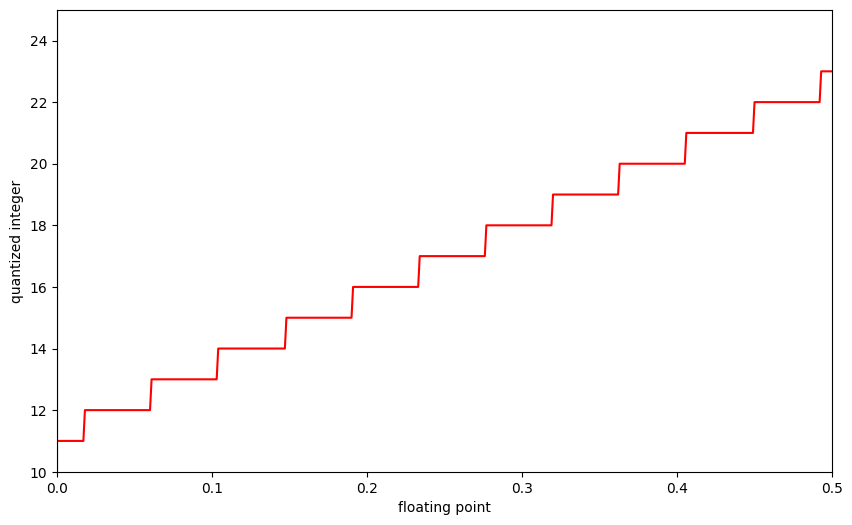

In [9]:
# Zoom in to see the effect of quantization:
plt.figure(figsize=(10, 6))
plt.plot(x, x_q, 'r')
plt.ylabel('quantized integer')
plt.xlabel('floating point')
plt.axhline(y=0, color='k')
plt.axvline(x=0, color='k')
plt.xlim(0, 0.5)
plt.ylim(10, 25)
plt.show()

Each step in the staircase corresponds to a discrete integer level: all floating-point values falling within the same interval are mapped to the same quantized representation, and the differences between them are irreversibly lost. Quantization therefore introduces an **approximation error**, but this error is not arbitrary. Since the mapping is performed through rounding, the reconstructed value can differ from the original one by at most **half of the quantization step**. In other words, the maximum quantization error is bounded by s/2. We can verify this numerically:

In [10]:
# Generate a range of floating point values within the original range
x = np.arange(min, max, 0.1).astype(float)

# Quantize and dequantize the values to evaluate the quantization error
x_q = quantization(x, s, z, min_q, max_q)
x_d = dequantization(x_q, s, z)

# Calculate the quantization error as the absolute difference between 
# the original and dequantized values
max_error = np.max(np.abs(x_d - x))

# Print the maximum quantization error and the half scale factor
print(f"Max quantization error : {max_error:.6f}")
print(f"Half scale factor (s/2): {s/2:.6f}")

Max quantization error : 0.021569
Half scale factor (s/2): 0.021569


### Weight compression

So far we have looked at quantization as a standalone operation. Now it is time to apply it to an actual neural network. In a network, the **weights** (the learned parameters stored in the model) are fixed after training and dominate the **storage cost** of the model. Interestingly, [experiments](./papers/(2016)%20-%20Deep%20Cpmpression,%20Compressing%20Deep%20Neural%20Networks%20with%20Pruning,%20Trained%20Quantization%20and%20Huffman%20Coding.pdf) show that weight values are rarely spread uniformly across a wide range, they tend to cluster tightly around zero, with only a few outliers. The following figure shows the weight distribution of the simple VGG16 model as an example:

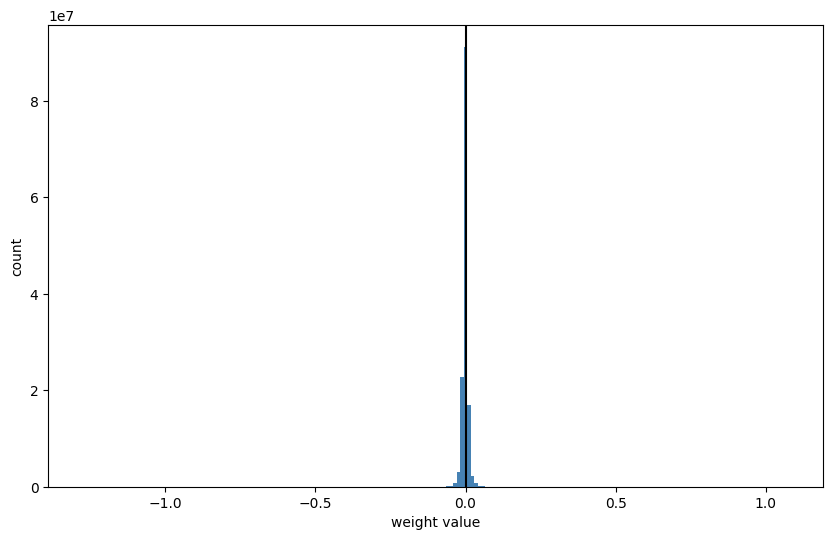

In [11]:
import torch
import torchvision.models as models
import matplotlib.pyplot as plt
import numpy as np

# Load pretrained VGG
vgg_model = models.vgg16(weights=models.VGG16_Weights.DEFAULT)

# Collect all weight values from convolutional and linear layers
weights = []
for module in vgg_model.modules():
    if isinstance(module, (torch.nn.Conv2d, torch.nn.Linear)):
        weights.append(module.weight.data.numpy().flatten())

# Concatenate all weight values into a single array
weights = np.concatenate(weights)

# Plot the distribution
plt.figure(figsize=(10, 6))
plt.hist(weights, bins=200, color='steelblue', edgecolor='none')
plt.xlabel('weight value')
plt.ylabel('count')
plt.axvline(x=0, color='k')
plt.show()

This tight concentration is precisely what makes quantization effective for weights. Because most values live in a narrow, predictable range, we can bin them into an 8-bit integer grid without losing the overall structure of the distribution: the network's learned representation remains largely intact after compression. In practice, we are binning the original floating point values of weights into an 8-bit encoding scheme:

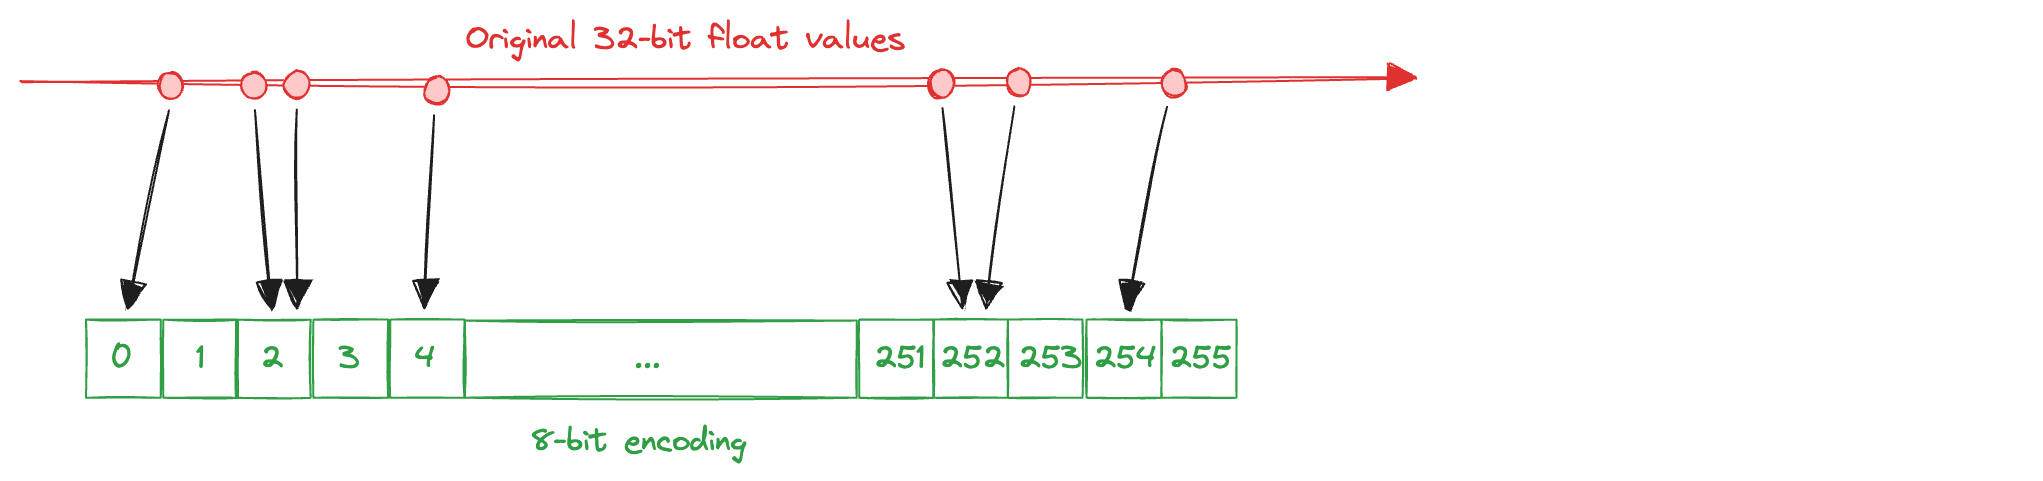

Now the network is actually 8 bits and we can save it in order to **shrunk the model size down by 4x**. Then when we start running it to do the inference, we take the 8-bit values and reconstruct them into a 32-bit floating point value:

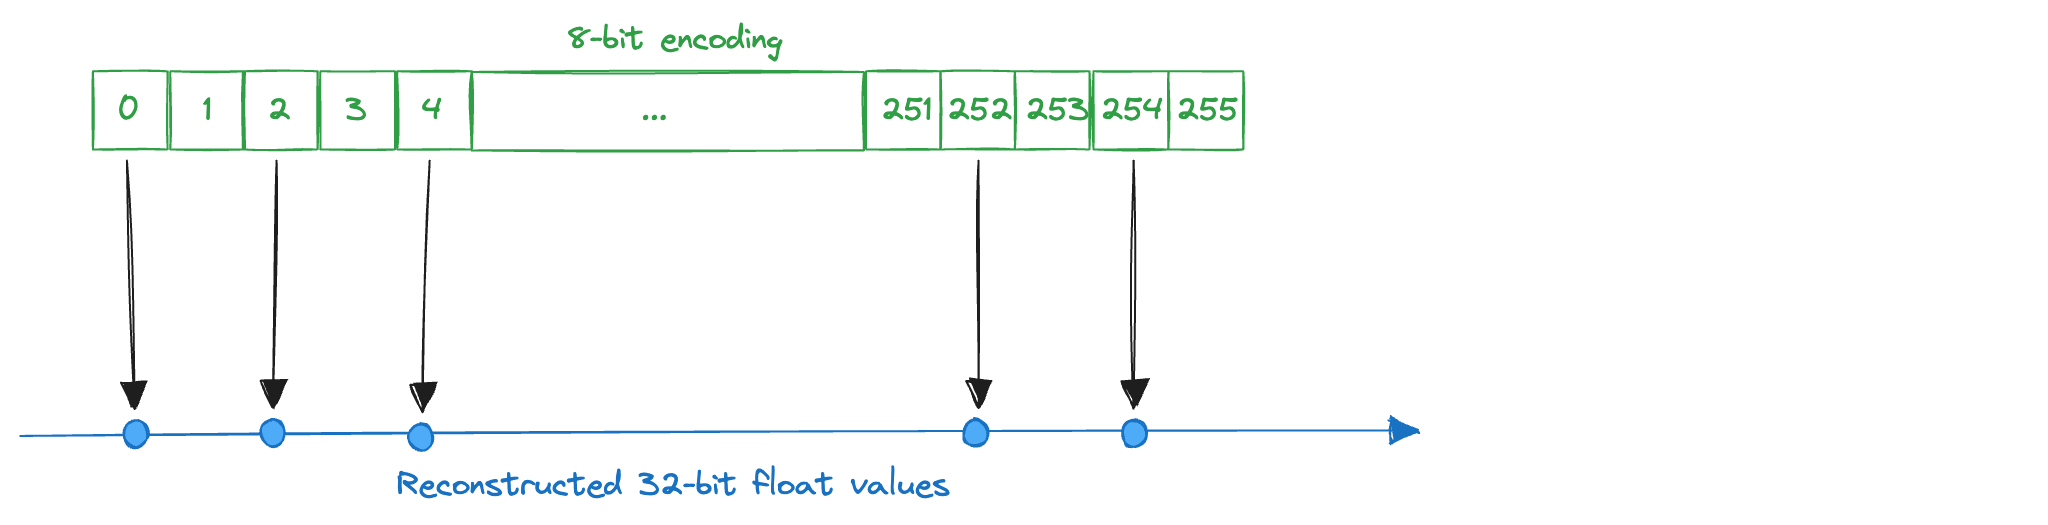

Notice that we can have some **side effects**. Sometimes we can have a situation where two floating point values are close to each other and they fall into the same integer bucket, and when we decompress the value, it comes into the same floating point value, and we **lost some resolution** that we previously have in the original. This is a trade-off we should take into account:

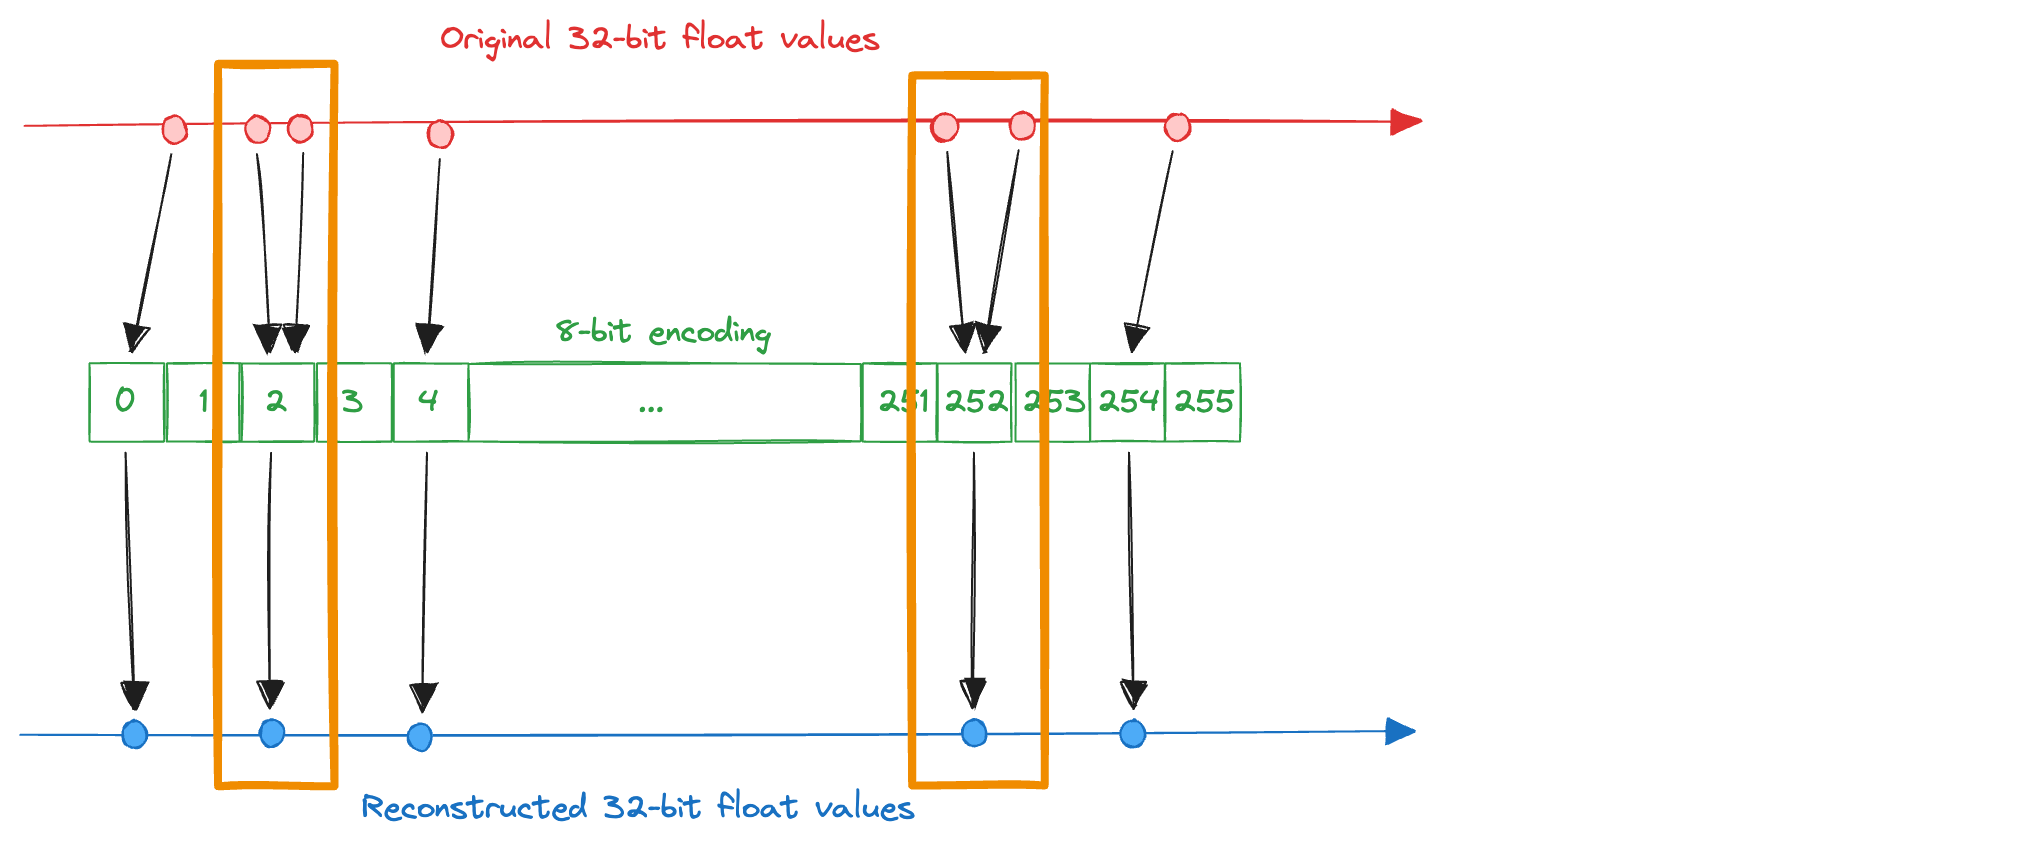

In the end, once the dequantization function finishes, we have a floating-point value back from the stored integer value, and then we can perform floating-point operations like in a standard neural network. The benefit is that the size of the model is smaller and in general if our scale is smaller, it is more likely to have smaller errors. This is the first step of the quantization scheme (**quantized weight compression**) and it is done for **size reduction** and we assume to have floating point arithmetic capability. 

### Quantized linear neuron

Weight-only quantization reduces storage, but the arithmetic during inference is still floating-point. To also **speed up computation**, we need to perform the operations directly in integer arithmetic. Consider a single layer with n input features, m samples, and q neurons. The output for one neuron on one sample is:

$\displaystyle \hat{y} = \sum_{k=0}^{n} \theta_k x_k + b$

which requires n multiply-accumulate operations plus one addition. Across all samples and neurons, the total cost is (m * q * n) operations and this has to run fast, potentially on constrained hardware. Substituting the dequantized expressions: 

$\displaystyle \theta_k = s_\theta(\theta_{q;k} - z_\theta)$ 

and 

$\displaystyle x_k = s_x(x_{q;k} - z_x)$ 

$\displaystyle b = s_b(b_q - z_b)$

the output becomes:

$\displaystyle \hat{y} = \sum\limits_{k=0}^{n} s_\theta (\theta_{q;k} - z_\theta) s_x (x_{q;k} - z_x) + s_b(b_q - z_b) =$ 

Expanding the product:

$\displaystyle \hat{y} = \sum\limits_{k=0}^{n} s_\theta (\theta_{q;k} - z_\theta) s_x (x_{q;k} - z_x) + s_b(b_q - z_b) =$ 

$\displaystyle = s_\theta s_x \sum\limits_{k=0}^{n} \left((\theta_{q;k} - z_\theta) (x_{q;k} - z_x)\right) + s_b(b_q - z_b) =$ 

$\displaystyle = s_\theta s_x \sum\limits_{k=0}^{n} \left( \theta_{q;k} x_{q;k} - \theta_{q;k} z_x - z_\theta x_{q;k} + z_\theta z_x \right) + s_b(b_q - z_b) =$ 

$\displaystyle = s_\theta s_x \left( \sum\limits_{k=0}^{n} \theta_{q;k} x_{q;k} - z_x \sum\limits_{k=0}^{n} \theta_{q;k} - z_\theta \sum\limits_{k=0}^{n} x_{q;k} + n z_\theta z_x  \right) + s_b(b_q - z_b)$

This decomposition reveals something useful. Three of the five terms depend only on the weights, not on the input sample:

$\displaystyle z_x \sum_{k=0}^{n} \theta_{q;k} \qquad n\, z_\theta z_x \qquad s_b(b_q - z_b)$

These can be computed once offline and reused for every sample The term 

$\displaystyle z_\theta \sum_{k=0}^{n} x_{q;k}$ 

depends on the input, but it is just a sum and no multiplications needed. The remaining core term:

$\displaystyle \sum_{k=0}^{n} \theta_{q;k} x_{q;k}$ 

is a standard dot product, but now entirely in **integer arithmetic**. This matters because integer multiply-accumulate operations are significantly faster than their floating-point equivalents in silicon, often by an order of magnitude. Combined with the fact that these operations can be parallelized across neurons and samples, and offloaded to dedicated integer hardware accelerators, the speedup in practice can be substantial.

There is one more piece to handle: the output of a neuron (**activation**) immediately becomes the input to the next layer. To keep the entire computation in integer arithmetic, we need the activation to also come out quantized. Introducing a dedicated scale and zero-point for the output activation:

$\displaystyle \hat{y}_q = \frac{\hat{y}}{s_y}+ z_y$

and substituting the full expression including the bias term, the quantized neuron becomes:

$\displaystyle \hat{y}_q = \frac{s_\theta s_x}{s_y} \left( \sum_{k=0}^{n} \theta_{q;k}\, x_{q;k} - z_x \sum_{k=0}^{n} \theta_{q;k} - z_\theta \sum_{k=0}^{n} x_{q;k} + n\, z_\theta z_x \right)+ \frac{s_b}{s_y}(b_q - z_b) + z_y$

Unfortunately, this introduces a new complication: the scale and zero-point for weights and inputs are known ahead of time, since the weight distribution is fixed after training and the input range can be calibrated. The activations, however, are trickier, since **their range depends on the actual data flowing through the network**. There are two ways to handle this:

- **Dynamic quantization** computes scale and zero-point for activations on the fly during each forward pass. The activations remain in floating-point and are converted to integers only for the computation, then converted back. This adds some overhead but requires no prior calibration data.

- **Static quantization** pre-computes scale and zero-point for every activation in the network using a small representative dataset, collected in a calibration step before deployment. This eliminates the runtime overhead entirely, but comes with a risk: if the calibration data is not representative of real inputs, the estimated ranges will be off, and inference accuracy will suffer.

We can write the full quantized neuron in Python as follows:

In [12]:
def quantized_neuron(theta_q, x_q, b_q,
                     s_x, z_x, 
                     s_theta, z_theta,  
                     s_b, z_b, 
                     s_y, 
                     z_y, 
                     min_q, max_q):
  
    # Number of input features
    n = theta_q.shape[0]
    
    # Upcast to int32 before accumulation to avoid overflow
    theta_q = theta_q.astype(np.int32)
    x_q     = x_q.astype(np.int32)

    # Core dot product
    # integer multiply-accumulate in int32
    dot_product  = np.dot(theta_q, x_q)
    
    # Correction for input zero-point
    # precomputable offline since weights are fixed
    offset_theta = z_x * np.sum(theta_q)
    
    # Correction for weight zero-point
    # depends on the input sample
    offset_x     = z_theta * np.sum(x_q)
    
    # Constant correction term
    # precomputable offline
    offset_const = n * z_theta * z_x

    # Bias contribution
    # precomputable offline since bias is fixed after training
    bias = s_b / s_y * (b_q - z_b)
    
    # Neuron output in integer form
    # weights and inputs only, bias added after rescaling
    y_int = dot_product - offset_theta - offset_x + offset_const

    # Rescale to output quantization grid, 
    # bias is added here because it lives on a different scale 
    # than the weight/input accumulation
    y_q = np.round(s_theta * s_x / s_y * y_int + bias + z_y).astype(np.int32)
    
    # clip to valid integer range
    y_q = np.clip(y_q, min_q, max_q)
    
    return y_q

We need to discuss two important implementation details. Even though inputs and weights are quantized to 8-bit integers, the dot product **accumulates many of these values together and the result can easily overflow**. Therefore the sum and multiply-accumulate operations must be performed in a **wider integer format** to prevent overflow. In practice, we upcast to INT32 before accumulation. It is exactly how real hardware works: the input registers are 8-bit, but the accumulator is 32-bit to prevent overflow. Morevover, the output of the integer computation **cannot be directly the output of the neuron**, because it is expressed in a different scale. It should be rescaled considering the correct activation scale and zero-point. This is a floating-point operation that cannot be avoided in software, since it involves dividing by the output scale which is a real-valued constant. In real hardware, **the ratio is precomputed** once before inference and approximated with a fixed-point multiplier, keeping the entire computation in integer arithmetic end to end. We can make an example comparing the results of a standard neuron with the one of a quantized neuron on a random input sample:

In [13]:
# Number of features
n = 3

# Range for random input samples, weights and bias
x_min,     x_max     = -1.0, 1.0
theta_min, theta_max = -1.0, 1.0
b_min,     b_max     = -1.0, 1.0

# Generate random input, weights and bias in the specified range
x     = np.random.uniform(low=x_min,     high=x_max,     size=n).astype(np.float32)
theta = np.random.uniform(low=theta_min, high=theta_max, size=n).astype(np.float32)
b     = np.float32(np.random.uniform(low=b_min, high=b_max))

# Reference output using standard floating-point arithmetic
y = float(np.dot(theta, x)) + float(b)
print(f'Floating-point neuron : {y:.3f}')

# Quantization parameters for inputs, weights and bias
s_x,     z_x,     x_min_q,     x_max_q     = generate_quantization_parameters(x_min,     x_max)
s_theta, z_theta, theta_min_q, theta_max_q = generate_quantization_parameters(theta_min, theta_max)
s_b,     z_b,     b_min_q,     b_max_q     = generate_quantization_parameters(b_min,     b_max)

# Quantize inputs, weights and bias
x_q     = quantization(x,     s_x,     z_x,     x_min_q,     x_max_q)
theta_q = quantization(theta, s_theta, z_theta, theta_min_q, theta_max_q)
b_q     = int(quantization(np.array([b]), s_b, z_b, b_min_q, b_max_q)[0])

# Quantization parameters for the output activation
# worst-case range: dot product bounded by n, bias bounded by b_max
y_min, y_max = -float(n) + b_min, float(n) + b_max
s_y, z_y, y_min_q, y_max_q = generate_quantization_parameters(y_min, y_max)

# Output of the quantized neuron
y_q = quantized_neuron(theta_q, x_q, b_q,
                       s_x, z_x,
                       s_theta, z_theta,
                       s_b, z_b,
                       s_y, z_y,
                       y_min_q, y_max_q)

# Dequantize the output and compare with the floating-point reference
y_d = float(dequantization(np.array([y_q]), s_y, z_y)[0])
print(f'Quantized neuron      : {y_d:.3f}')
print(f'Quantization error    : {abs(y - y_d):.3f}')

Floating-point neuron : 0.815
Quantized neuron      : 0.831
Quantization error    : 0.016


The quantized neuron produces a result very close to the floating-point reference. This is the combined effect of three sources of quantization noise: the rounding of the input, the rounding of the weights, and the rounding of the output activation. Each contributes a small error of at most and they add up to a total that remains well within acceptable bounds, as long as the true output stays inside the calibrated range. When it does not, clipping takes over and the error can be much larger, which is why choosing a good output range is just as important as the quantization itself.

### Quantized activation functions

Linear layers are not the only building blocks of a neural network, most architectures interleave them with **non-linear activation functions** such as ReLU. How do we handle these in a fully quantized pipeline? The naive approach is to dequantize the input, apply the activation in floating-point, and requantize the output. This works, but defeats much of the purpose: in a deep network there is an activation after almost every layer, so the constant back-and-forth between integer and floating-point arithmetic would dominate the inference time. A better approach is to derive a **quantized version of each activation function** directly in the integer domain. 

As an example, consider the ReLU function, which is in general form defined as:

$\displaystyle \text{ReLU}(x,\, x_t,\, y_v,\, k) = \begin{cases} y_v & \text{if } x < x_t \\ y_v + k(x - x_t) & \text{if } x \geq x_t \end{cases}$

In [14]:
def relu(x, x_t, y_v, k):
    return np.where(x < x_t, y_v, y_v + k * (x - x_t))

The standard ReLU is simply the special case 

$\displaystyle x_t = 0 \quad y_v = 0 \quad k = 1$:

$\displaystyle \text{ReLU}(x,\, 0,\, 0,\, 1) = \begin{cases} 0 & \text{if } x < 0 \\ x & \text{if } x \geq 0 \end{cases}$

This generalized form may look unnecessarily complex at first, but it will turn out to be exactly the right abstraction for expressing the quantized version.

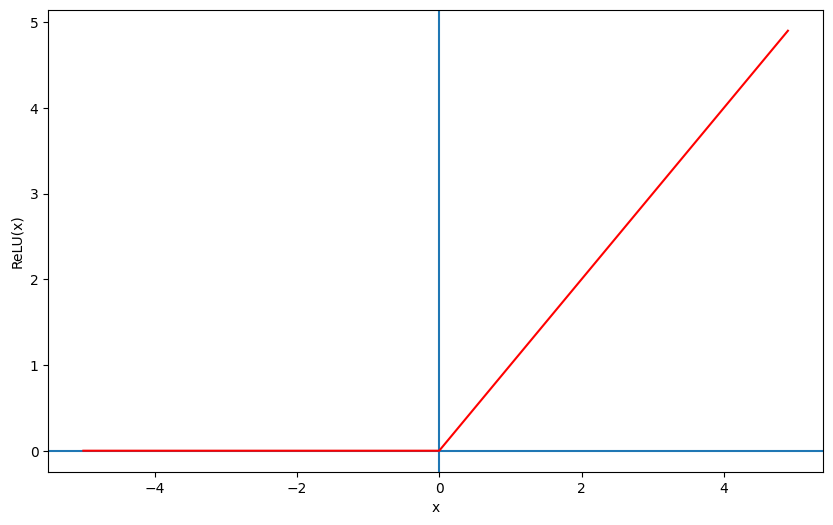

In [15]:
# Set parameters for the standard ReLU function
x_t = 0
y_v = 0
k = 1

# Generate a range of input values
x = np.arange (-5, 5, 0.1)

# Calculate the ReLU output for the input values
y = relu(x, x_t, y_v, k)

# Plot the ReLU function
plt.figure(figsize=(10, 6))
plt.axhline(y=0)
plt.axvline(x=0)
plt.plot(x, y, 'r')
plt.ylabel('ReLU(x)')
plt.xlabel('x')
plt.show()

We can now derive the quantized version of ReLU, which takes as input the quantized aoutput of the neuron:

$\displaystyle a = \text{ReLU}(y)$

We can substitute the dequantized expressions for both a and y:

$\displaystyle s_a(a_q - z_a) = \text{ReLU}(s_y(y_q - z_y),\, 0,\, 0,\, 1) = \begin{cases} 0 & \text{if } s_y(y_q - z_y) < 0 \\ s_y(y_q - z_y) & \text{if } s_y(y_q - z_y) \geq 0 \end{cases}$

Since $s_y > 0$, the condition $s_y(y_q - z_y) < 0$ simplifies to $y_q < z_y$, giving:

$\displaystyle s_a(a_q - z_a) = \begin{cases} 0 & \text{if } y_q < z_y \\ s_y(y_q - z_y) & \text{if } y_q \geq z_y \end{cases}$

Solving for $a_q$:

$\displaystyle a_q = \begin{cases} z_a & \text{if } y_q < z_y \\ z_a + \dfrac{s_y}{s_a}(y_q - z_y) & \text{if } y_q \geq z_y \end{cases}$

This is exactly the generalized ReLU defined earlier, with threshold $x_t = z_y$, floor value $y_v = z_a$, and slope $k = s_y / s_a$:

$\displaystyle a_q = \text{ReLU}\!\left(y_q,\; z_y,\; z_a,\; \frac{s_y}{s_a}\right)$

The quantized ReLU operates entirely on integers, with no dequantization needed.

In [16]:
def quantized_relu(y_q, s_y, z_y, s_a, z_a):

    # Use the generalized ReLU formula with the appropriate 
    # parameters for threshold, floor value, and slope
    a_q = relu(y_q, z_y, z_a, s_y / s_a).astype(np.int32)
    
    # Return the quantized output
    return a_q

We can plot the quantized ReLU function:

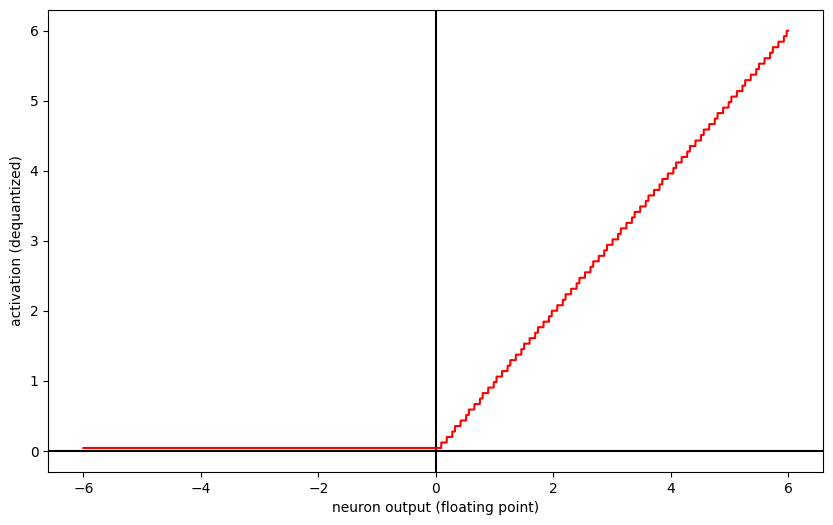

In [17]:
# Quantization parameters for the neuron output (ReLU input)
y_min, y_max = -6.0, 6.0
s_y, z_y, y_q_min, y_q_max = generate_quantization_parameters(y_min, y_max)

# Quantization parameters for the activation output
a_min, a_max = -10.0, 10.0
s_a, z_a, a_q_min, a_q_max = generate_quantization_parameters(a_min, a_max)

# Generate a range of floating point values for the neuron output (ReLU input)
y = np.arange(y_min, y_max, 0.001)

# Quantize the neuron output, 
# apply quantized ReLU, 
# then dequantize for plotting
y_q = quantization(y, s_y, z_y, y_q_min, y_q_max)
a_q = quantized_relu(y_q, s_y, z_y, s_a, z_a)
a_d = dequantization(a_q, s_a, z_a)

plt.figure(figsize=(10, 6))
plt.axhline(y=0, color='k')
plt.axvline(x=0, color='k')
plt.plot(y, a_d, 'r')
plt.xlabel('neuron output (floating point)')
plt.ylabel('activation (dequantized)')
plt.show()

Negative inputs are mapped to zero, and positive inputs pass through linearly with the characteristic staircase pattern from quantization. The small non-zero value visible on the negative side is not an error, it is the effect of the zero-point, which shifts the integer zero slightly away from the floating-point zero after dequantization. The staircase on the positive side reflects the discrete integer steps of the output activation grid. We can zoom in around zero to see the effect of the zero-point more clearly:

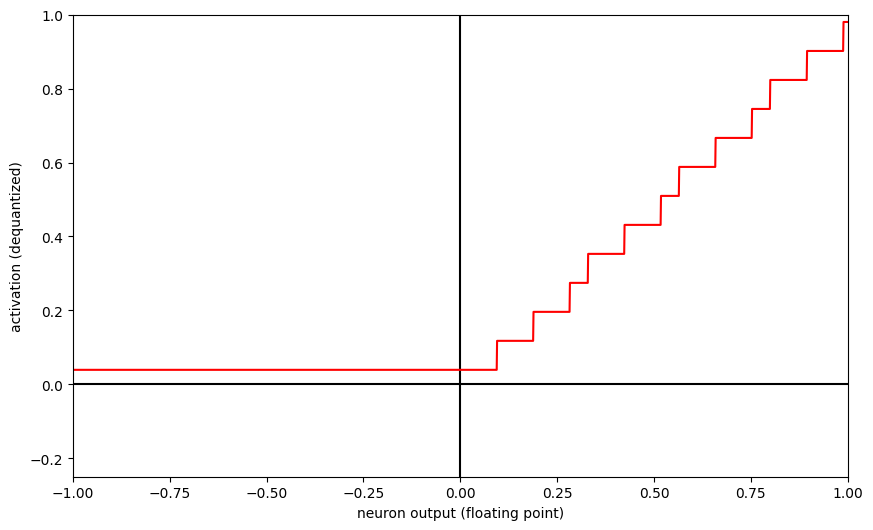

In [18]:
plt.figure(figsize=(10, 6))
plt.axhline(y=0, color='k')
plt.axvline(x=0, color='k')
plt.plot(y, a_d, 'r')
plt.xlabel('neuron output (floating point)')
plt.ylabel('activation (dequantized)')
plt.xlim(-1, 1)
plt.ylim(-0.25, 1)
plt.show()

Beyond speed, quantization of operations also reduces **power consumption**. Floating-point arithmetic requires more transistor switching activity than integer arithmetic, and on battery-powered or always-on devices this difference matters enormously. A final benefit is **portability**: not all embedded processors include a floating-point unit, and those that do may implement it with different precision or performance characteristics. Integer arithmetic, by contrast, is a universal baseline available on virtually every processor, from high-end microcontrollers down to the smallest microcontrollers. A quantized model can therefore **run anywhere**, without any assumption about the underlying hardware.

### Performance and accuracy trade-offs

To measure the impact of quantization on accuracy and performance, we build and train a small fully-connected network on MNIST from scratch:

In [19]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Create a pipeline to convert MINST images to tenors
transform = transforms.Compose([
    transforms.ToTensor(),
])

# Load the MINST training and test datasets, applying the transformation 
train_dataset = datasets.MNIST(root='./data', train=True,  download=True, transform=transform)
test_dataset  = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

# Create data loaders for training and testing
train_loader  = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader   = DataLoader(test_dataset,  batch_size=64, shuffle=False)

The network is intentionally simple (two hidden layers with ReLU activations) so that we can implement the quantized forward pass explicitly using the functions developed earlier, layer by layer.

In [20]:
import torch
import torch.nn as nn

class SimpleNet(nn.Module):
    def __init__(self):
        super().__init__()

        # A simple fully-connected network with two hidden layers
        self.fc1 = nn.Linear(784, 128)
        self.fc2 = nn.Linear(128, 64)

        # Output layer with 10 classes for MNIST
        self.fc3 = nn.Linear(64, 10)

        # ReLU activation function
        self.relu = nn.ReLU()

    def forward(self, x):

        # Flatten the input image from (batch_size, 1, 28, 28) 
        # to (batch_size, 784)
        x = x.view(-1, 784)

        # Pass through the first fully-connected layer and apply ReLU
        x = self.relu(self.fc1(x))

        # Pass through the second fully-connected layer and apply ReLU
        x = self.relu(self.fc2(x))

        # Pass through the output layer 
        # (no activation, since we'll apply softmax in the loss function)
        x = self.fc3(x)

        # Return the output logits
        return x

# Instantiate the model
model = SimpleNet()

# Print the model architecture
print(model)

SimpleNet(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (fc3): Linear(in_features=64, out_features=10, bias=True)
  (relu): ReLU()
)


Train and evaluate the model in full precision:

In [21]:
import torch.optim as optim

# Define the loss function as cross-entropy loss, 
# which is suitable for multi-class classification
criterion = nn.CrossEntropyLoss()

# Use the Adam optimizer to update the model parameters during training
optimizer = optim.Adam(model.parameters(), lr=1e-3)

# Function to train the model for one epoch
def train(model, loader, criterion, optimizer):
    model.train()
    total_loss = 0
    for images, labels in loader:
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(loader)

# Function to evaluate the model on the test set and calculate accuracy
def evaluate(model, loader):
    model.eval()
    correct = 0
    with torch.no_grad():
        for images, labels in loader:
            outputs = model(images)
            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
    return correct / len(loader.dataset)

# Train for a few epochs and print the loss and accuracy after each epoch
n_epochs = 5
for epoch in range(n_epochs):
    loss = train(model, train_loader, criterion, optimizer)
    accuracy = evaluate(model, test_loader)
    print(f'Epoch {epoch+1}/{n_epochs}  loss: {loss:.4f}  accuracy: {accuracy:.4f}')

Epoch 1/5  loss: 0.3543  accuracy: 0.9474
Epoch 2/5  loss: 0.1477  accuracy: 0.9589
Epoch 3/5  loss: 0.1004  accuracy: 0.9717
Epoch 4/5  loss: 0.0741  accuracy: 0.9749
Epoch 5/5  loss: 0.0566  accuracy: 0.9753


We now extract the weights and biases of each layer directly from the trained model and quantize them independently. Each layer gets its own scale factor and zero-point, computed from the actual range of its weights and biases. This per-layer calibration ensures that the quantization grid is as fine as possible for each set of values rather than using a single coarse grid for the entire network.

In [22]:
# Extract weights and biases from the trained model
W1 = model.fc1.weight.detach().numpy()
b1 = model.fc1.bias.detach().numpy()
W2 = model.fc2.weight.detach().numpy()
b2 = model.fc2.bias.detach().numpy()
W3 = model.fc3.weight.detach().numpy()
b3 = model.fc3.bias.detach().numpy()

# Quantization parameters and quantized weights for layer 1
s_W1, z_W1, W1_min_q, W1_max_q = generate_quantization_parameters(float(W1.min()), float(W1.max()))
s_b1, z_b1, b1_min_q, b1_max_q = generate_quantization_parameters(float(b1.min()), float(b1.max()))
W1_q = np.array([quantization(row, s_W1, z_W1, W1_min_q, W1_max_q) for row in W1])
b1_q = quantization(b1, s_b1, z_b1, b1_min_q, b1_max_q)

# Quantization parameters and quantized weights for layer 2
s_W2, z_W2, W2_min_q, W2_max_q = generate_quantization_parameters(float(W2.min()), float(W2.max()))
s_b2, z_b2, b2_min_q, b2_max_q = generate_quantization_parameters(float(b2.min()), float(b2.max()))
W2_q = np.array([quantization(row, s_W2, z_W2, W2_min_q, W2_max_q) for row in W2])
b2_q = quantization(b2, s_b2, z_b2, b2_min_q, b2_max_q)

# Quantization parameters and quantized weights for layer 3
s_W3, z_W3, W3_min_q, W3_max_q = generate_quantization_parameters(float(W3.min()), float(W3.max()))
s_b3, z_b3, b3_min_q, b3_max_q = generate_quantization_parameters(float(b3.min()), float(b3.max()))
W3_q = np.array([quantization(row, s_W3, z_W3, W3_min_q, W3_max_q) for row in W3])
b3_q = quantization(b3, s_b3, z_b3, b3_min_q, b3_max_q)

We also need quantization parameters for the inputs and activations at each layer. The input range is fixed, since MNIST pixels are in [0, 1],  so its parameters can be computed directly. The activation ranges after each hidden layer and at the output are not known in advance and should ideally be estimated through a calibration pass on real data. Here we use conservative fixed bounds as a starting point, keeping in mind that if the true range exceeds these values, clipping will occur and accuracy will suffer:

In [23]:
# Quantization parameters for input (pixel values in [0, 1])
s_x, z_x, x_min_q, x_max_q = generate_quantization_parameters(0.0, 1.0)

# Quantization parameters for activations after each layer
s_a1, z_a1, a1_min_q, a1_max_q = generate_quantization_parameters(-20.0, 20.0)
s_a2, z_a2, a2_min_q, a2_max_q = generate_quantization_parameters(-20.0, 20.0)

# Quantization parameters for output layer activations
s_out, z_out, out_min_q, out_max_q = generate_quantization_parameters(-50.0, 50.0)

We can now implement the quantized forward pass. Each layer applies the quantized_neuron() function to every output unit, followed by the quantized_relu() function for the hidden layers. The final layer has no activation, its output is dequantized and passed to argmax to obtain the predicted class:

In [24]:
def quantized_forward(x_float):

    # Quantize the input
    x_q = quantization(x_float, s_x, z_x, x_min_q, x_max_q).astype(np.int32)

    # Layer 1: linear + bias + ReLU
    y1_q = np.array([quantized_neuron(W1_q[j], x_q, b1_q[j],
                                      s_x, z_x, 
                                      s_W1, z_W1,
                                      s_b1, z_b1,
                                      s_a1, z_a1,
                                      a1_min_q, a1_max_q)
                    for j in range(W1_q.shape[0])])
    a1_q = quantized_relu(y1_q, s_a1, z_a1, s_a1, z_a1)

    # layer 2: linear + bias + ReLU
    y2_q = np.array([quantized_neuron(W2_q[j], a1_q, b2_q[j],
                                      s_a1, z_a1,
                                      s_W2, z_W2,
                                      s_b2, z_b2,
                                      s_a2, z_a2,
                                      a2_min_q, a2_max_q)
                    for j in range(W2_q.shape[0])])
    a2_q = quantized_relu(y2_q, s_a2, z_a2, s_a2, z_a2)

    # Layer 3: linear + bias only (output layer, no activation)
    out_q = np.array([quantized_neuron(W3_q[j], a2_q, b3_q[j],
                                       s_a2, z_a2,
                                       s_W3, z_W3,
                                       s_b3, z_b3,
                                       s_out, z_out,
                                       out_min_q, out_max_q)
                    for j in range(W3_q.shape[0])])

    # Dequantize the output logits
    out = dequantization(out_q, s_out, z_out)

    # Return the index of the maximum logit as the predicted class
    return np.argmax(out)

We evaluate both models on the test set and compare their accuracy. For speed, the quantized forward pass is run on a subset of samples, since the naive Python loop over individual neurons makes it significantly slower than the vectorized PyTorch implementation, which is expected since our goal here is correctness and transparency, not performance:

In [25]:
# Number of test samples to evaluate (use a subset for speed)
n_samples = 5000

# Number of correct predictions for the quantized model
correct = 0

# Evaluate the quantized model on the test set
for i, (image, label) in enumerate(test_dataset):
    if i >= n_samples:
        break
    x = image.numpy().flatten()
    pred = quantized_forward(x)
    if pred == label:
        correct += 1

# Calculate accuracy for the quantized model
quantized_accuracy = correct / n_samples

# Evaluate the original floating-point model on the
baseline_accuracy  = evaluate(model, test_loader)

# Compare the accuracies of the floating-point and quantized models
print(f'Floating-point accuracy : {baseline_accuracy:.4f}')
print(f'Quantized accuracy      : {quantized_accuracy:.4f}')
print(f'Accuracy drop           : {baseline_accuracy - quantized_accuracy:.4f}')

Floating-point accuracy : 0.9753
Quantized accuracy      : 0.9694
Accuracy drop           : 0.0059


This is a remarkably small degradation considering that every weight, bias, and activation in the network has been compressed from 32-bit floating-point to 8-bit integers, and the entire forward pass runs in integer arithmetic. The residual error is purely due to quantization noise accumulating across the three layers, and could be further reduced by tightening the activation ranges through proper calibration. Beyond accuracy, quantization directly reduces the memory footprint of the model. Each float32 parameter takes 4 bytes, while each int8 parameter takes only 1, so the theoretical size reduction is exactly:

In [26]:
# floating-point model: each weight is a float32
params = sum(p.numel() for p in model.parameters())
float_size_kb = params * np.dtype(np.float32).itemsize / 1024

# quantized model: each weight is an int8
int8_size_kb = params * np.dtype(np.int8).itemsize / 1024

print(f'Floating-point model : {float_size_kb:.2f} KB  ({np.dtype(np.float32)})')
print(f'Quantized model      : {int8_size_kb:.2f} KB  ({np.dtype(np.int8)})')
print(f'Size reduction       : {float_size_kb / int8_size_kb:.1f}x')

Floating-point model : 427.29 KB  (float32)
Quantized model      : 106.82 KB  (int8)
Size reduction       : 4.0x


Measuring inference speedup is not meaningful in this context: our quantized forward pass is implemented as a Python loop over individual neurons, which is orders of magnitude slower than PyTorch's vectorized floating-point operations. The integer arithmetic advantage only materializes when the quantized operations are executed on hardware or a runtime that natively supports them, such as a microcontroller, a mobile processor, or a dedicated inference library like.

### Quantization-aware training

The approach we have used so far is called **post-training quantization**: the model is trained normally in floating-point, and quantization is applied only afterwards. It is the simplest approach and can be applied to any existing model without retraining. However, it comes with an **inherent limitation**: the model was never exposed to quantization noise during training, so it has no opportunity to adapt to it. As we saw, the accuracy drop is small but unavoidable, because the round-trip through quantization and dequantization is lossy:

$\displaystyle x = D(Q(x, s_x, z_x), s_x, z_x) + \Delta_x$

where we have added the quantization error explicitly as a separate term that captures the difference between the original value and the reconstructed value after quantization.  A natural question is whether we can do better. Through [**quantization-aware training**](./papers/(2018)%20-%20Quantized%20Neural%20Networks-%20Training%20Neural%20Networks%20with%20Low%20Precision%20Weights%20and%20Activations.pdf) (QAT), the idea is to **simulate the effect of quantization during training** itself, so that the network **learns to be resilient to it**. Concretely, we insert a quantize-then-dequantize operation around each tensor during the forward pass:

$\displaystyle \hat{x} = D(Q(x, s_x, z_x), s_x, z_x) = s_x\!\left(\text{clip}\!\left(\text{round}\!\left(\frac{x}{s_x} + z_x\right), m_q, M_q\right) - z_x\right)$

The data types remain floating-point throughout and the weights are still updated by gradient descent as usual, but the quantization error is now present in every forward pass, so the network is **implicitly penalized for solutions that are sensitive to it**. Over the course of training, the network learns to distribute its weights in ways that survive quantization more gracefully. The key challenge is that quantization operation is not differentiable, the rounding step has zero gradient almost everywhere, so backpropagation through a quantize-dequantize block would produce no useful gradient signal and the weights would never be updated. The standard solution is the **straight-through estimator** (STE): in the forward pass we quantize normally, but in the backward pass we pretend the rounding never happened and pass the gradient through unchanged, as if the operation were the identity function:

In [27]:
def differentiable_quantize(x, bits=8, signed=True):

    # quantization range
    if signed:
        min_q, max_q = -2**(bits-1), 2**(bits-1)-1
    else:
        min_q, max_q = 0, 2**bits-1

    # scale and zero-point from the current tensor range
    x_min, x_max = x.min().item(), x.max().item()
    s = (x_max - x_min) / (max_q - min_q)
    z = (max_q * x_min - x_max * min_q) / (x_min - x_max)

    # scale the input to the integer grid
    x_scaled = x / s + z

    # straight-through estimator: round in forward, identity in backward
    # In the backward pass .detach() stops the gradient of the rounding 
    # correction, so the gradient flows only through x as if rounding 
    # never happened
    x_q = x_scaled + (torch.round(x_scaled) - x_scaled).detach()

    # clip to valid integer range
    x_q = torch.clamp(x_q, min_q, max_q)

    # dequantize back to floating-point
    return s * (x_q - z)

The QAT network has the same architecture as SimpleNet, but its forward pass applies the differentiable quantize function to the weights, biases, and activations at each layer:

In [28]:
import torch.nn.functional as F

class QATSimpleNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 10)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = x.view(-1, 784)

        # Layer 1 — simulate quantization of weights, bias and activation
        a1 = self.relu(F.linear(x,
                                differentiable_quantize(self.fc1.weight),
                                differentiable_quantize(self.fc1.bias)))
        a1 = differentiable_quantize(a1)

        # Layer 2 — simulate quantization of weights, bias and activation
        a2 = self.relu(F.linear(a1,
                                differentiable_quantize(self.fc2.weight),
                                differentiable_quantize(self.fc2.bias)))
        a2 = differentiable_quantize(a2)

        # Layer 3 — simulate quantization of weights and bias, no activation
        out = F.linear(a2,
                       differentiable_quantize(self.fc3.weight),
                       differentiable_quantize(self.fc3.bias))
        return out
    
# Instantiate the QAT model
qat_model = QATSimpleNet()

# Define the optimizer for training the QAT model
optimizer_qat = torch.optim.Adam(qat_model.parameters(), lr=1e-3)

The training loop is identical to the one used for the baseline model, the entire QAT logic is encapsulated inside the forward pass:

In [29]:
for epoch in range(n_epochs):
    qat_model.train()
    total_loss = 0
    for images, labels in train_loader:
        optimizer_qat.zero_grad()
        outputs = qat_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer_qat.step()
        total_loss += loss.item()
    accuracy = evaluate(qat_model, test_loader)
    print(f'Epoch {epoch+1}/{n_epochs}  loss: {total_loss/len(train_loader):.4f}  accuracy: {accuracy:.4f}')

Epoch 1/5  loss: 0.3500  accuracy: 0.9500
Epoch 2/5  loss: 0.1427  accuracy: 0.9639
Epoch 3/5  loss: 0.0971  accuracy: 0.9712
Epoch 4/5  loss: 0.0737  accuracy: 0.9741
Epoch 5/5  loss: 0.0567  accuracy: 0.9745


After training, we extract and quantize the weights exactly as before, the difference is that the weights now come from a model that was trained with quantization noise injected at every layer.

In [30]:
W1 = qat_model.fc1.weight.detach().numpy()
b1 = qat_model.fc1.bias.detach().numpy()
W2 = qat_model.fc2.weight.detach().numpy()
b2 = qat_model.fc2.bias.detach().numpy()
W3 = qat_model.fc3.weight.detach().numpy()
b3 = qat_model.fc3.bias.detach().numpy()

s_W1, z_W1, W1_min_q, W1_max_q = generate_quantization_parameters(float(W1.min()), float(W1.max()))
s_b1, z_b1, b1_min_q, b1_max_q = generate_quantization_parameters(float(b1.min()), float(b1.max()))
W1_q = np.array([quantization(row, s_W1, z_W1, W1_min_q, W1_max_q) for row in W1])
b1_q = quantization(b1, s_b1, z_b1, b1_min_q, b1_max_q)

s_W2, z_W2, W2_min_q, W2_max_q = generate_quantization_parameters(float(W2.min()), float(W2.max()))
s_b2, z_b2, b2_min_q, b2_max_q = generate_quantization_parameters(float(b2.min()), float(b2.max()))
W2_q = np.array([quantization(row, s_W2, z_W2, W2_min_q, W2_max_q) for row in W2])
b2_q = quantization(b2, s_b2, z_b2, b2_min_q, b2_max_q)

s_W3, z_W3, W3_min_q, W3_max_q = generate_quantization_parameters(float(W3.min()), float(W3.max()))
s_b3, z_b3, b3_min_q, b3_max_q = generate_quantization_parameters(float(b3.min()), float(b3.max()))
W3_q = np.array([quantization(row, s_W3, z_W3, W3_min_q, W3_max_q) for row in W3])
b3_q = quantization(b3, s_b3, z_b3, b3_min_q, b3_max_q)

We evaluate the QAT model after quantization and compare it with the baseline and post-training quantized results:

In [31]:
correct = 0
for i, (image, label) in enumerate(test_dataset):
    if i >= n_samples:
        break
    pred = quantized_forward(image.numpy().flatten())
    if pred == label:
        correct += 1

# Calculate accuracy for the quantized QAT model
qat_accuracy = correct / n_samples

# Compare the accuracies of the floating-point, quantized, and QAT models
print(f'Floating-point accuracy    : {baseline_accuracy:.4f}')
print(f'Post-training quantized    : {quantized_accuracy:.4f}  (drop: {baseline_accuracy - quantized_accuracy:.4f})')
print(f'Quantization-aware trained : {qat_accuracy:.4f}  (drop: {baseline_accuracy - qat_accuracy:.4f})')

Floating-point accuracy    : 0.9753
Post-training quantized    : 0.9694  (drop: 0.0059)
Quantization-aware trained : 0.9642  (drop: 0.0111)


QAT is not guaranteed to always outperform post-training quantization, it introduces an additional source of noise that can either help or hurt depending on the architecture and the data. Interestingly, it sometimes produces a model that is **even more accurate than the original floating-point baseline**, because the injected noise acts as **a form of regularization**, similar in spirit to dropout. Whether QAT pays off in practice is something that has to be verified empirically: it is **one more hyperparameter** in the training process.

## Pruning

Neural networks are usually **over-parameterized**, meaning they contain far more weights and neurons than strictly necessary. This redundancy translates directly into wasted computation and memory at inference time. [**Pruning**](./papers/(1989)%20-%20Optimal%20Brain%20Damage.pdf) addresses this by selectively removing the least important connections or neurons, much like a gardener cutting back a plant to encourage healthier, more efficient growth. The goal is a smaller, faster model that retains most of the original accuracy.

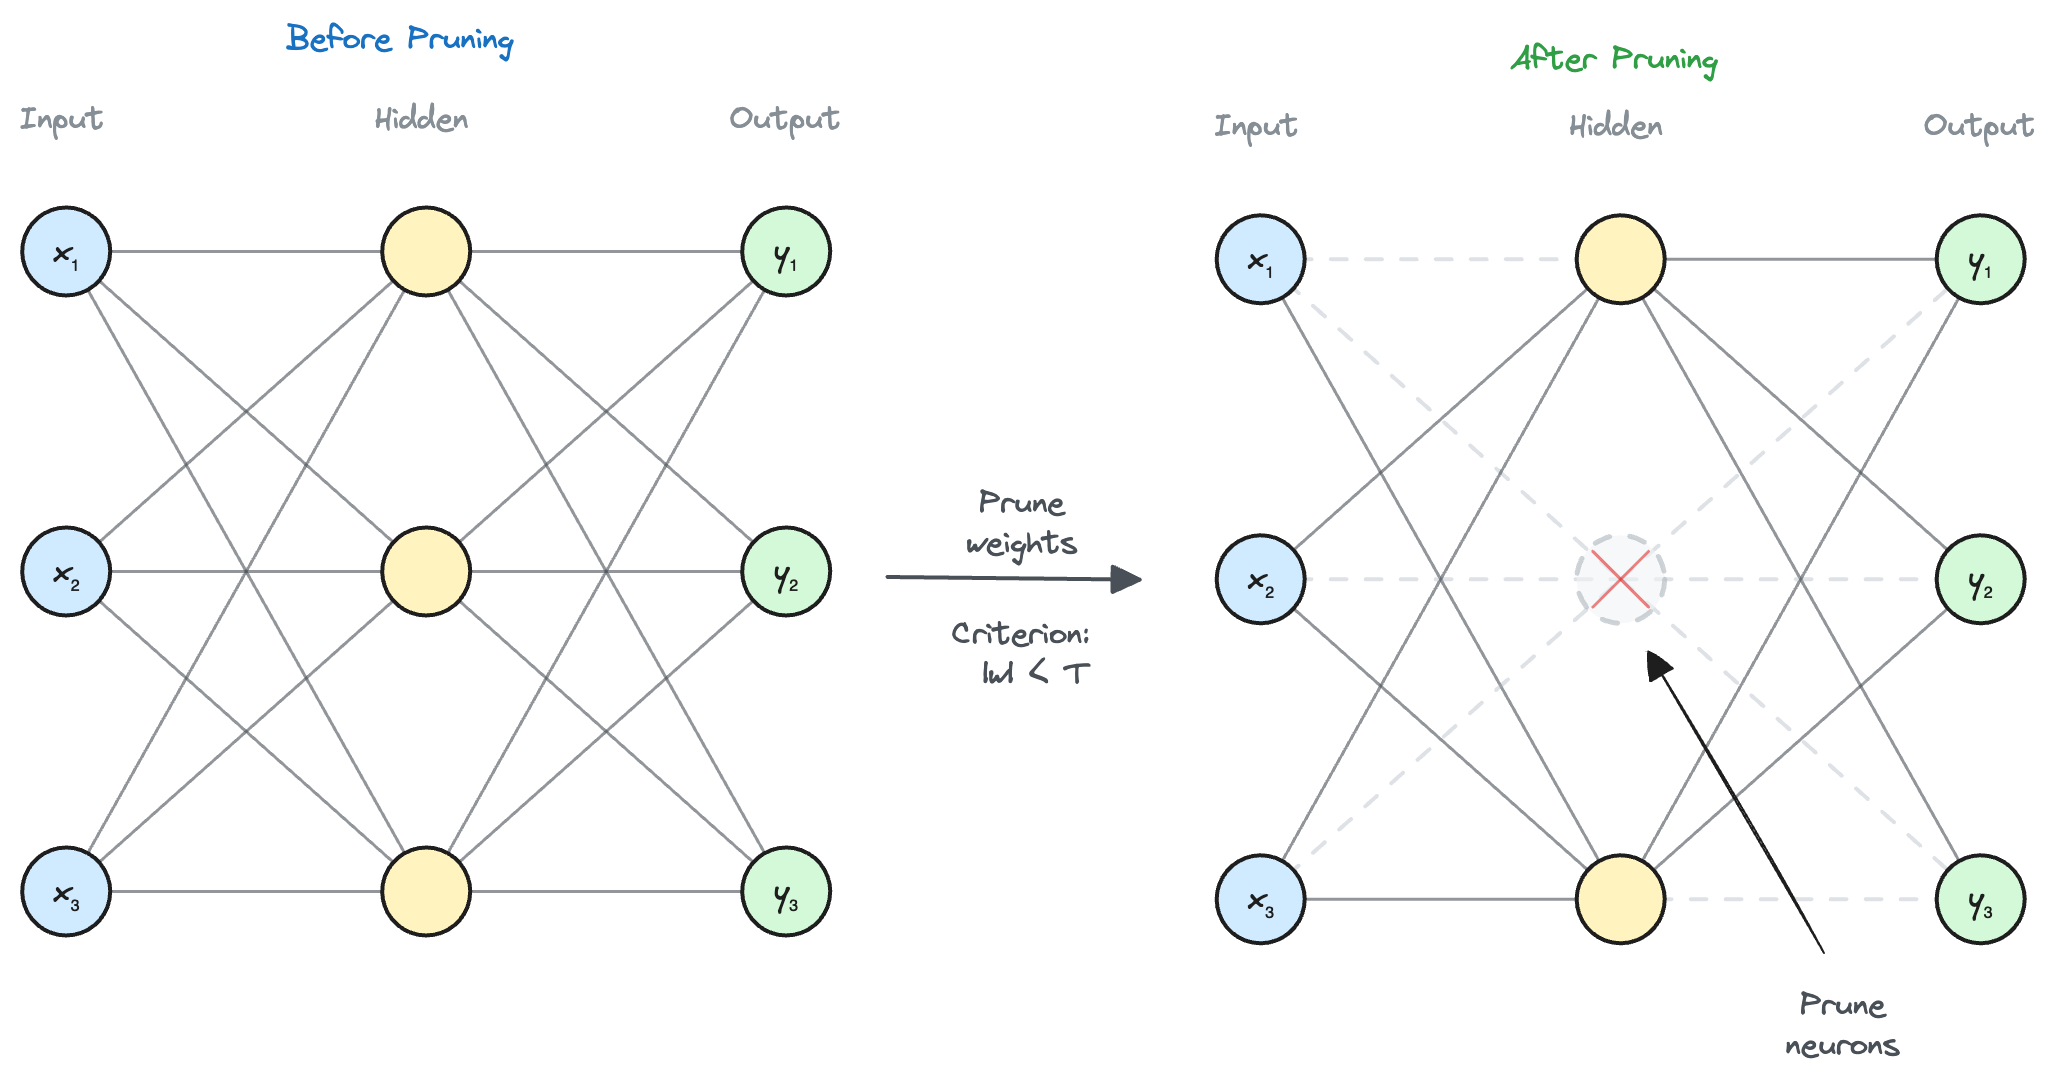

### Non-significant parameters

To prune effectively, we first need a notion of what makes a parameter unimportant. Consider a simple example:

$\displaystyle f(x) = x + 5x^2$

The two terms have very different weights. Intuitively, the larger-weight term dominates: small changes to the smaller coefficient barely affect the function's behavior. This suggests that **weight magnitude** is a natural proxy for importance. To better show this, we can define the function with the first weight as a variable:

In [33]:
def f(x, a):
    return a * x + 5 * x**2

We can plot the value of the function as we vary the first weight with values far from the weight of the second term:

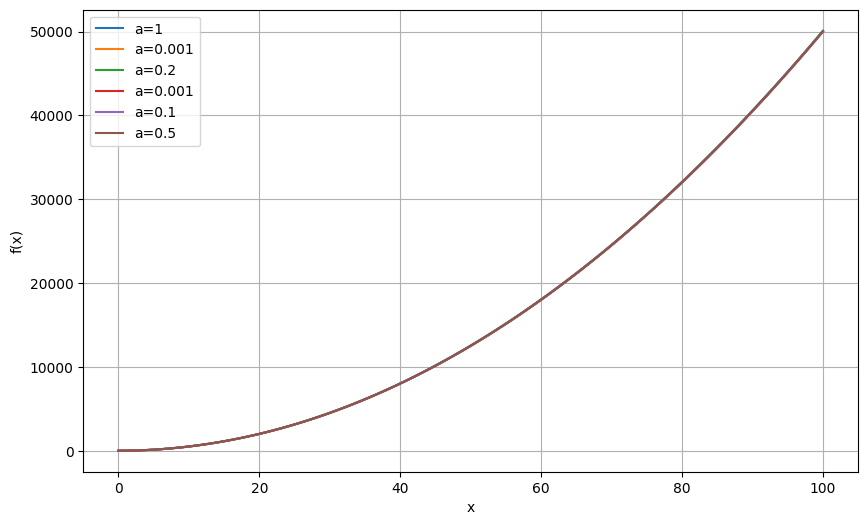

In [37]:
# Define a range of values for the coefficient a to see how it affects the function
a_values = [1, 0.001, 0.2, 0.001, 0.1, 0.5]

# Define a range of x values to plot the function
x = np.linspace(0, 100, 100) 

# Create a plot
plt.figure(figsize=(10, 6))

# Plot the function for each value of a
for a in a_values:
    plt.plot(x, f(x, a), label=f'a={a}')

# Finalize the plot
plt.xlabel('x')
plt.ylabel('f(x)')
plt.legend()
plt.grid(True)
plt.show()

This is the core idea behind pruning: parameters with small magnitudes contribute little to the model's output and can be removed with minimal impact on accuracy.

### Magnitude-based Pruning

In a neural network, we can identify non-significant parameters by inspecting the distribution of weights across layers. For example we can consider the distribution of weights in the first hidden layer of the model we trained on MNIST:

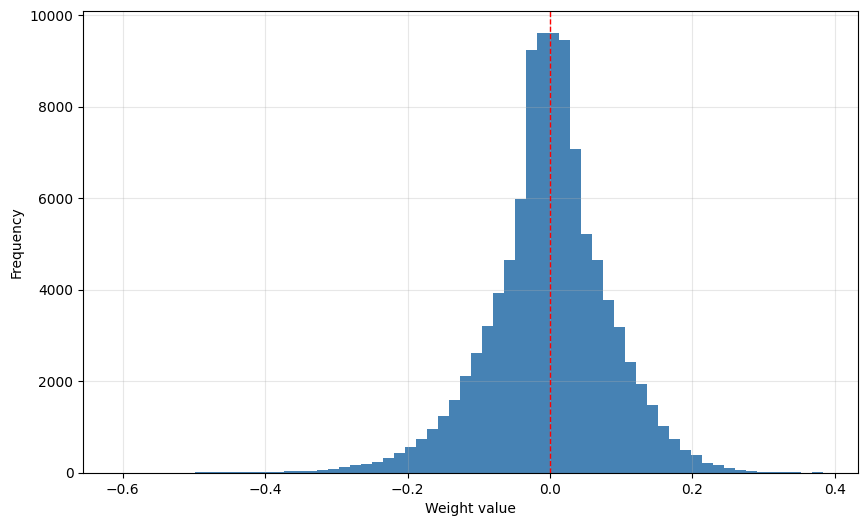

In [40]:
def plot_weights_distribution(model, layer_name):

    # Select the specified layer from the model
    layer = getattr(model, layer_name)

    # Extract the weights from the layer and flatten them into a 1D array
    weights = layer.weight.data.cpu().numpy().flatten()
    
    # Plot the distribution of weights using a histogram
    plt.figure(figsize=(10, 6))
    plt.hist(weights, bins=64, color='steelblue', edgecolor='none')
    plt.xlabel('Weight value')
    plt.ylabel('Frequency')
    plt.axvline(0, color='red', linewidth=1, linestyle='--')
    plt.grid(True, alpha=0.3)
    plt.show()

# Plot the distribution of weights for the first fully-connected layer (fc1) of the model
plot_weights_distribution(model, layer_name='fc1')

The weights are approximately normally distributed around zero. Weights close to zero received small gradient updates during training and contribute little to the model's output, these are the pruning candidates. The simplest strategy is **magnitude-based pruning**: we rank all weights by their absolute value and zero out the smallest ones. The fraction of weights removed is controlled by a **sparsity level**, for example, a sparsity of 0.5 means half the weights are set to zero:

In [41]:
import copy

def prune_model(model, sparsity=0.5):

    # Create a deep copy of the model to avoid modifying the original
    pruned_model = copy.deepcopy(model)
    
    # For each module in the model
    for name, module in pruned_model.named_modules():

        # Check the layer types, since not all layers have weights 
        # we want to prune (e.g. BatchNorm has learnable scale 
        # and shift parameters that control normalization: zeroing those 
        # out would break the layer entirely). 
        if isinstance(module, (nn.Linear, nn.Conv2d)):

            # Get the weights of the layer 
            weights = module.weight.data
            
            # Compute the pruning threshold based on the specified sparsity level
            threshold = torch.quantile(weights.abs(), sparsity)
            
            # Create a mask that identifies which weights to keep (those above the threshold)
            mask = weights.abs() >= threshold

            # Apply the mask to the weights, effectively zeroing out the pruned weights
            module.weight.data *= mask
    
    # Return the pruned model 
    return pruned_model

We can now prune the model and inspect how the weight distribution changes, the spike at zero should grow in proportion to the sparsity level:

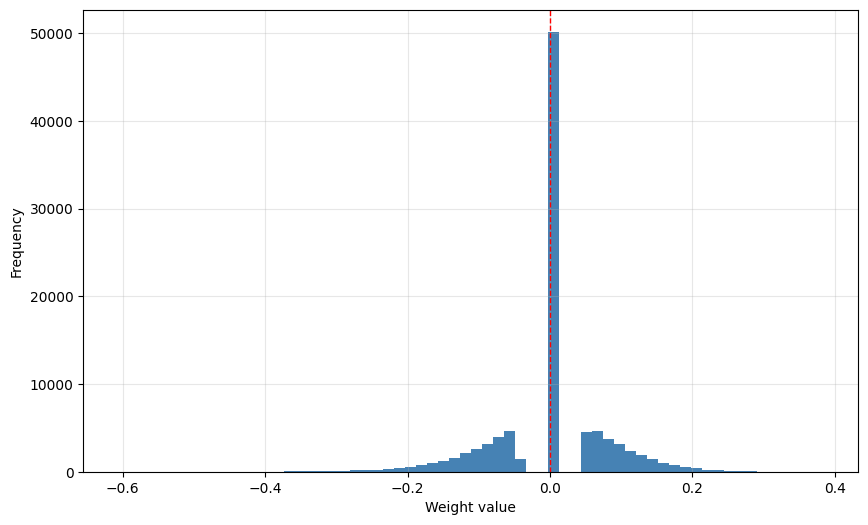

In [ ]:
# Create a pruned version of the model with some sparsity
pruned_model = prune_model(model, sparsity=0.5)

# Plot the new weights distribution
plot_weights_distribution(pruned_model, layer_name='fc1')

Pruning inevitably introduces a trade-off: the more weights we remove, the smaller and faster the model becomes, but at some point accuracy starts to degrade. The key question is *how much sparsity we can afford before the performance drop becomes unacceptable*. The following code sweeps over a range of sparsity levels and measures the accuracy change relative to the original model:

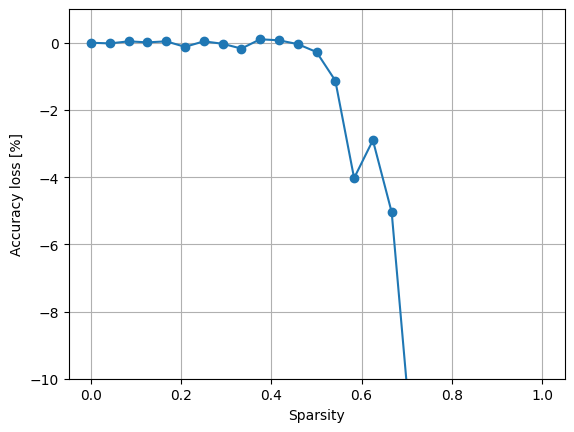

In [45]:
sparsity_levels = np.linspace(0, 1, 25)
accuracies = []

for sparsity in sparsity_levels:
    pruned_model = prune_model(model, sparsity=sparsity)
    pruned_accuracy = evaluate(pruned_model, test_loader)
    accuracies.append((pruned_accuracy - baseline_accuracy) / baseline_accuracy * 100)

plt.plot(sparsity_levels, accuracies, marker='o')
plt.xlabel('Sparsity')
plt.ylabel('Accuracy loss [%]')
plt.ylim((-10, 1))
plt.grid(True)
plt.show()

Therefore, various pruning algorithms and **heuristics** have been developed to guide the pruning process and find the optimal trade-off between size and performance. The **weight magnitude criterion** is quite intuitive and surprisingly efficient. Another criterion is the **magnitude of the gradient**, we can accumulate gradients over a minibatch of training data and prune on the basis of the product between this gradient and the corresponding weight of each parameter. One final aspect to take into consideration is whether the chosen criterion is **applied globally** to all parameters, or if it is computed independently for each layer. While global pruning has proven many times to yield better results, it can lead to layer collapse. A simple way to avoid this problem is to resort to layer-wise local pruning, namely pruning the same rate at each layer (as we have done before), when the used method cannot prevent layer collapse.

When we apply this idea to a deep network, we need to observe that **different layers have varying levels of tolerance to pruning**. For instance, the deeper layers can usually tolerate more extensive pruning. This is because these layers are primarily responsible for refining the decisions and predictions based on the features already identified and processed by the preceding layers. They don’t need as many weights to compute the final output, as the majority of critical information has already been distilled at this point. On the other hand, the initial layers are typically more sensitive to pruning. This is due to their foundational role in the model: these layers are responsible for extracting and processing the low-level features from the input data. These features form the basis for all subsequent computations and decision-making processes within the model.

It's often advisable to **retrain the network for a few extra epochs**, with the lowest learning rate, to give it a chance to recover from the loss in performance induced by pruning. Usually, the pruning and retraing can be **iterated**, with each time a growing pruning rate. Iterating has shown to improve performance, at the cost of extra computation and training time. 

Finally, simply pruning weights can lead to a sparse model (where only a small fraction of parameters are non-zero) with disconnected neurons, which may result in suboptimal performance. Most frameworks and hardware **cannot accelerate sparse matrices computation**, meaning that no matter how many zeros WE fill the parameterS with, it will not impact the actual cost of the network. To mitigate this issue, **structured pruning** can be employed. It involves pruning in a way that **directly alters the architecture of the network, removing entire neurons** (or groups of neurons, like convolution filters) instead of individual weights.

## Knowledge distillation

**[Knowledge distillation]()** is tecnique in which an already trained complex and high perfroming model is used to govern a smaller model on what to do and how to do a particular task, without losing accuracy. This is exactly similar to a teacher transferring his knowledge to a student in a school. The student has no prior experience in executing the task, however he executes it with the knowledge imparted by the teacher in handling similar situations. Similarly, through knowledge distillation, smaller models are trained using the knowledge acquired by a large model:

![](images/distillation.png)

The **transfer of knowledge** is comparable to the lectures given by the teacher to the students: we train the smaller model based on the outputs received through training the larger models. In order to understand what knowledge gets distilled from the teacher to the learner, consider an example of MNIST dataset. Let’s pick a sample picture of number 3. In training data, this number translates to a corresponding one-hot-vector like [0,0,0,1,0,0,0,0,0,0] (**hard targets**). This simply tells that the number in the image is 3, but fails to explicitly mention anything about the shape of number 3, like the shape of 3 is similar to 8. Using an already trained model, **we can get the distribution of probabilities across all classes, even the wrong ones**. So, the teacher can instruct the student about the fact that the shape of the number in the example image is 3, but he can also suggests that the shape of 3 is quite similar to the shape of numbers 8 and 0 (**soft targets**). Then we can train the student model taking into account the generated output of the teacher model. In the classification problems, the teacher outputs logits that are computed for each class, we use a softmax layer to normalize these logits into probabilities:

$\displaystyle p_i = \frac{e^{z_i/T}}{\sum_{j} e^{z_j/T}}$

where T is the **temperature parameter** and can be used to control the influence of the teacher. Higher temperature results in a softer probability distribution over classes. In order to understand the effect of the temperature parameter, we can plot the probability distribution for different values of T in a situation with three classes:

- Dataset values: 0, 1, 0
- Teacher output: 0.1, 0.7. 0.2 

In [68]:
dataset_values = np.array([0, 1, 0])
teacher_probs = np.array([0.1, 0.7, 0.2])

In [69]:
def softmax(p, T):
    exp_p = np.exp(p / T)
    return exp_p / np.sum(exp_p)

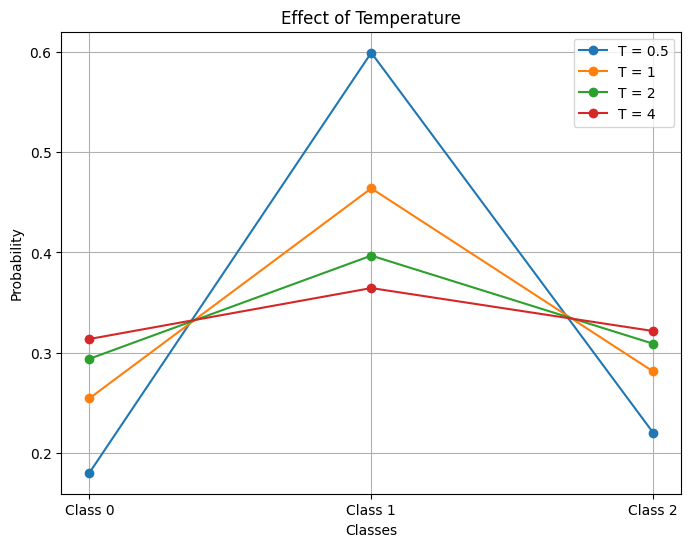

In [70]:
T_values = [0.5, 1, 2, 4]
class_indices = np.arange(len(dataset_values))

plt.figure(figsize=(8, 6))
for T in T_values:
    student_probs = softmax(teacher_probs, T)
    plt.plot(class_indices, student_probs, marker='o', label=f"T = {T}")

plt.xlabel("Classes")
plt.ylabel("Probability")
plt.title("Effect of Temperature")
plt.xticks(class_indices, [f"Class {i}" for i in class_indices])
plt.legend()
plt.grid(True)
plt.show()

The main idea is to train the student model adding a contribution to the loss (**student loss**) based on the difference between its output and the output of the teacher model (**distillation loss**):

$\displaystyle L = (1-\alpha) SL(y_{true}, y_{student}) + \alpha  DL(p_{teacher},p_{student})$

where $\alpha$ is a hyperparameter that controls the influence of the distillation loss.

![](images/distillation-loss.png)

But how we can calculate the distillation loss? Mathematically we can use the **Kullback-Leibler divergence** to measure how much information we lose when we choose the approximation. It is a measure of how one probability distribution differs from a second, reference probability distribution. KL Divergence has its origins in information theory. The primary goal of information theory is to quantify how much information is in data, and the most important metric is called Entropy, typically denoted as H and defined as 

$\displaystyle H(p) = - \sum_{i} p(i) \log p(i)$

We can use this notion to quantify how much information we lost when we use the student distribution Q instead of the teacher distribution P, given that the actual distribution is P:

$\displaystyle D_{KL}(P||Q) = \sum_{i} p(i) (\log p(i) - \log q(i)) = \sum_{i} p(i) \log \frac{p(i)}{q(i)}$

It may be tempting to think of KL divergence as a distance metric, however we cannot use KL divergence to measure the distance between two distributions. The reason for this is that KL divergence is not symmetric.

In [71]:
def kl_divergence(p, q):
    return np.sum(np.where(p != 0, p * np.log(p / q), 0))

As an example, the KL divergence between some normal distributions with differen means and same standard deviation is:

In [72]:
from scipy.stats import norm

x = np.arange(-10, 10, 0.001)

p = norm.pdf(x, 0, 2)
q1 = norm.pdf(x, 0.5, 2)
q2 = norm.pdf(x, 1, 2)
q3 = norm.pdf(x, 2, 2)

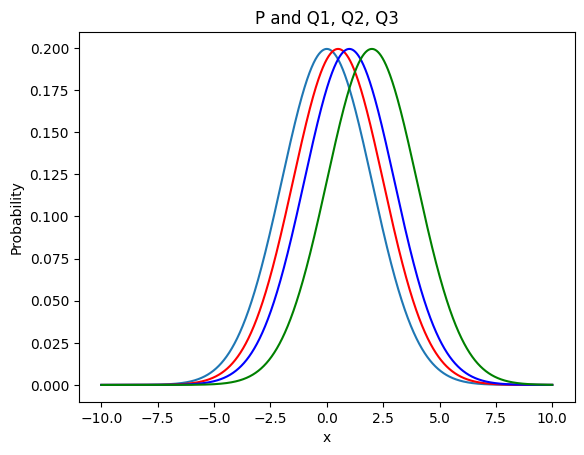

In [73]:
plt.title('P and Q1, Q2, Q3')
plt.plot(x, p)
plt.plot(x, q1, c='red')
plt.plot(x, q2, c='blue')
plt.plot(x, q3, c='green')
plt.xlabel("x")
plt.ylabel("Probability")
plt.show()

In [74]:
print('KL(P||Q1) = %1.3f' % kl_divergence(p, q1))
print('KL(P||Q2) = %1.3f' % kl_divergence(p, q2))
print('KL(P||Q3) = %1.3f' % kl_divergence(p, q3))

KL(P||Q1) = 31.250
KL(P||Q2) = 125.000
KL(P||Q3) = 500.000


We can plot the KL divergence value as a function of the difference of mean of the two normal distributions:

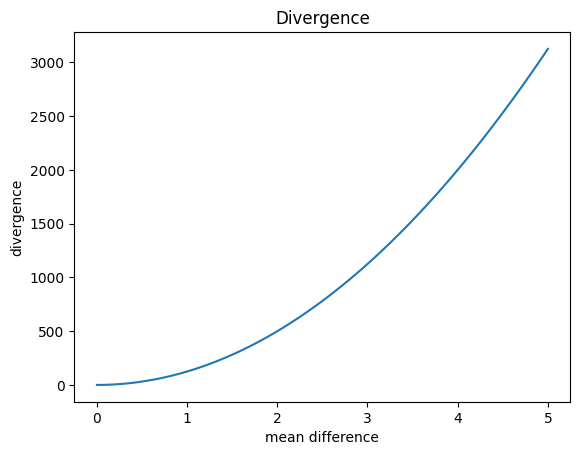

In [75]:
q_mean_range = np.linspace(0, 5, 100)

kl_values = []
for q_mean in q_mean_range:
    q = norm.pdf(x, q_mean, 2)
    kl_values.append(kl_divergence(p, q))

plt.title('Divergence')
plt.xlabel("mean difference")
plt.ylabel("divergence")
plt.plot(q_mean_range, kl_values)
plt.show()


Using the runnging example of MNIST dataset, we can create a teacher model and a cheap and small student model:

In [76]:
teacher_model = keras.Sequential([
  keras.layers.InputLayer(input_shape=(28, 28)),
  keras.layers.Reshape(target_shape=(28, 28, 1)),
  keras.layers.Conv2D(filters=12, kernel_size=(3, 3), activation='relu'),
  keras.layers.MaxPooling2D(pool_size=(2, 2)),
  keras.layers.Flatten(),
  keras.layers.Dense(10)
])

In [77]:
teacher_params = teacher_model.count_params()
print("Total number of teacher parameters:", teacher_params)

Total number of teacher parameters: 20410


In [78]:
student_model = keras.Sequential([
  keras.layers.InputLayer(input_shape=(28, 28)),
  keras.layers.Flatten(),
  keras.layers.Dense(3, activation="relu"),
  keras.layers.Dense(10)
])

# make some copy of the student model for later comparison
student_scratch_model = keras.models.clone_model(student_model)
student_limited_model = keras.models.clone_model(student_model)

In [79]:
student_params = student_model.count_params()
print("Total number of student parameters:", student_params)

Total number of student parameters: 2395


We assume that the teacher is trained and fixed. Thus, we start by training the teacher model on the training set in the usual way:

In [80]:
teacher_model.compile(optimizer='adam', 
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

In [81]:
results = teacher_model.fit(train_images, train_labels, epochs=3, validation_split=0.1, verbose=1)

Epoch 1/3
1688/1688 [==============================] - 5s 3ms/step - loss: 0.3034 - accuracy: 0.9143 - val_loss: 0.1342 - val_accuracy: 0.9640
Epoch 2/3
1688/1688 [==============================] - 5s 3ms/step - loss: 0.1359 - accuracy: 0.9609 - val_loss: 0.0968 - val_accuracy: 0.9728
Epoch 3/3
1688/1688 [==============================] - 5s 3ms/step - loss: 0.0986 - accuracy: 0.9717 - val_loss: 0.0782 - val_accuracy: 0.9790


We use the teacher to prepare the soft targets dataset:

In [82]:
temperature = 0.8

teacher_outputs = teacher_model.predict(train_images)
soft_targets = tf.nn.softmax(teacher_outputs / temperature)

1875/1875 [==============================] - 2s 752us/step


To focus on the distillation power, we set the $\alpha$ parameter to 1, which means that the distillation loss is the only contribution to the loss calculatoin. We define a custom loss function:

In [83]:
def distillation_loss(soft_targets, y_pred):
    y_pred_soft = tf.nn.softmax(y_pred / temperature)
    loss = tf.reduce_mean(tf.keras.losses.kullback_leibler_divergence(soft_targets, y_pred_soft))
    return loss

We compile the student model in order to use the custom loss fucntion:

In [84]:
student_model.compile(optimizer='adam', 
              loss=distillation_loss,
              metrics=['accuracy'])

Finally, we train the student model on the new **transfer dataset**:

In [85]:
results = student_model.fit(train_images, soft_targets, epochs=3, validation_split=0.1, verbose=1)

Epoch 1/3
1688/1688 [==============================] - 2s 752us/step - loss: 1.1039 - accuracy: 0.5971 - val_loss: 0.6969 - val_accuracy: 0.7542
Epoch 2/3
1688/1688 [==============================] - 1s 657us/step - loss: 0.6820 - accuracy: 0.7540 - val_loss: 0.5823 - val_accuracy: 0.7918
Epoch 3/3
1688/1688 [==============================] - 1s 667us/step - loss: 0.6251 - accuracy: 0.7690 - val_loss: 0.5505 - val_accuracy: 0.7908


We can evaluate and compere the accuracy of the two models on the test set:

In [86]:
def evaluate_model(model, x_test, y_test):
    predictions = np.argmax(model.predict(x_test, verbose=0), axis=1)
    true_classes = np.argmax(y_test, axis=1) if len(y_test.shape) > 1 else y_test
    accuracy = np.mean(true_classes == predictions)
    return accuracy

In [87]:
teacher_accuracy = evaluate_model(teacher_model, test_images, test_labels)
print('Teacher test accuracy:', teacher_accuracy)

student_accuracy = evaluate_model(student_model, test_images, test_labels)
print('Student test accuracy:', student_accuracy)

Teacher test accuracy: 0.9749
Student test accuracy: 0.7658


In order to better understand the power of knowledge distillation, we train the student models using a dataset with one of the classes removed. The teacher model was trained with the whole dataset. This means that the student model never encounter the removed class examples during its training, but thanks to knowledge distillation, it can be able to identify this class:

In [88]:
keep_indices = np.where(train_labels != 3)[0]

train_images_filtered = train_images[keep_indices]
train_labels_filtered = train_labels[keep_indices]

In [89]:
student_limited_model.compile(optimizer='adam', 
              loss=distillation_loss,
              metrics=['accuracy'])

In [90]:
temperature = 0.8

teacher_outputs_filtered = teacher_model.predict(train_images_filtered)
soft_targets_filtered = tf.nn.softmax(teacher_outputs_filtered / temperature)

1684/1684 [==============================] - 1s 845us/step


In [91]:
results = student_limited_model.fit(train_images_filtered, soft_targets_filtered, epochs=3, validation_split=0.1, verbose=1)

Epoch 1/3
1516/1516 [==============================] - 2s 788us/step - loss: 1.0940 - accuracy: 0.5909 - val_loss: 0.6894 - val_accuracy: 0.7423
Epoch 2/3
1516/1516 [==============================] - 1s 661us/step - loss: 0.6736 - accuracy: 0.7463 - val_loss: 0.5716 - val_accuracy: 0.8008
Epoch 3/3
1516/1516 [==============================] - 1s 661us/step - loss: 0.5783 - accuracy: 0.7990 - val_loss: 0.5012 - val_accuracy: 0.8361


We test the model only on a subset of the test set composed by the removed class:

In [92]:
mask = (test_labels == 3)

test_images_3 = test_images[mask]
test_labels_3 = test_labels[mask]

As we can see, the student model is able to identify the removed class, even if it has never seen it during the training. This is the power of knowledge distillation.

In [93]:
student_limited_accuracy = evaluate_model(student_limited_model, test_images_3, test_labels_3)
print('Student limited test accuracy:', student_accuracy)

Student limited test accuracy: 0.7658


We can also train an equivalent student model from scratch without the teacher, in order to check if it can identify the removed class:

In [94]:
student_scratch_model.compile(optimizer='adam', 
                              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                              metrics=['accuracy'])

In [95]:
results = student_scratch_model.fit(train_images_filtered, train_labels_filtered, epochs=3, validation_split=0.1, verbose=1)

Epoch 1/3
1516/1516 [==============================] - 2s 732us/step - loss: 1.2778 - accuracy: 0.6034 - val_loss: 0.8428 - val_accuracy: 0.7808
Epoch 2/3
1516/1516 [==============================] - 1s 620us/step - loss: 0.8017 - accuracy: 0.7838 - val_loss: 0.6610 - val_accuracy: 0.8298
Epoch 3/3
1516/1516 [==============================] - 1s 617us/step - loss: 0.7032 - accuracy: 0.8024 - val_loss: 0.6017 - val_accuracy: 0.8402


As expected, the student model trained from scratch is not able to identify the removed class.

In [96]:
student_scratch_accuracy = evaluate_model(student_scratch_model, test_images_3, test_labels_3)
print('Student scratch test accuracy:', student_scratch_accuracy)

Student scratch test accuracy: 0.0


The performance of the student model are worse than the teacher model since it has far less parameters, however it is smaller and it has :

In [97]:
teacher_model.save("./models/teacher_model.keras")
student_model.save("./models/student_model.keras")

In [98]:
print("Teacher model in kB:", os.path.getsize('./models/teacher_model.keras') / float(2**10))
print("Student model in kB:", os.path.getsize('./models/student_model.keras') / float(2**10))

Teacher model in kB: 102.1435546875
Student model in kB: 27.5693359375


## Keywords Spotting

Typically, when we are dealing with machines that have a full conversation with you, there are large and power hungry automatic speech recognition models. Keyword spotting is not one of those. It falls in the realm of overall speech recognition, but it is a critical front-end in order to wake a more complex model that is sitting behind the scenes.

<img src="./images/01.png" width="500">


When we say "Ok, Google" or "Alexa" you are wake-up the machine that then performs the full automatic speech recognition. In this particular scenario, we have a microphone that is continuously listening (only for the keyword, it is s not constantly recording). W are only thinking about one microphone, but in reality we have billions of keywords to be recognized on a regular day. Imagine if every single one  were actually being processed up in the cloud. This is not possible.

<img src="./images/03.png" width="600">

We don't need all these devices and their keywords to goes on the cloud, instead what we really want  is to come up with an architecture that allows us to provide that sort of keyword spotting capability
such a way that it scales billions of users. So we have to somehow figure out how to be able to run that keyword spotting task on a efficient local embedded device.

Then, if the keyword is detected locally and if the local model is confident enough that it is really a keyword, the command we say after, for example "show me the calendar", is managed by the full speech recognition system usually on to the cloud, where there is speech-to-text converting the words that we say into text, which are then used by the machine in order to figure something out and then be able to come back to us and then do text-to-speech where the machine speaks back to us. 

<img src="./images/02.png" width="600">


The part after the keyword spotting requires to do natural language processing because we need to understand what exactly what we are trying to ask, ant is can be a rather complicated process. But all the computation starts with the recoggnition of the keyword.

The key thing that keyword spotting really enables is that by running the keyword spotting application directly at the end point, near the microphone on an embedded device we're effectively **acting as a filter**, liminting the amount of data that is actually going up to the cloud effectively improving the overall system efficiency.

<img src="./images/04.png" width="600">



We can consider some of the challenges and constraints that we have in design an effective keyword spotting device:
- **Latency**: we need to provide a result quickly. Our brain can only focus on things for about 100/200 milliseconds, after that it automatically switches off and goes on to doing other things. So, the **responsiveness** of the system is crucial in order to provide a quality of experience that meets that expectation.
- **Bandwidth**: we want to minimize the amount of data movement. In any computing system, we have data and compute, it's the data movement that it is really costly, computing is actually cheap. So we want to minimize that data movement, and we don't want to send every single word captured by the device all the way up into the cloud where we have the datacenter to process that data, and then bring it back. Because it's not only slow, it is also very power consuming in moving that data. The more local we keep the data, the better it is from a battery perspective.
- **Accuracy**: the device is continuously listening to us, and we want it to show a feedback only when it's actually heard the keyword at the right time. We don't want false positives and neither we want false negatives. So accuracy is extremely critical.
- **Personalization**: the device is simply listening to sounds, and it is trying to find interesting patterns that happen to resemble a word that might match the keyword. Our sound can sometimes be similar as some sort of background sound. So we need to assure that the devide is able to only
respond to the user voice and not any background noise that might seemingly look like that. We can push personalization to an extreme: we might want the device to unlock only when it hears we
say the keyword and no others. In that case, the model will learn not only the keyword but also how to recognize that it's you that are talking.
- **Privacy**: when data is going up to the cloud, there is a remote chance that them  get compromised. So security and privacy is something that we got to protect.
- **Battery**: embedded devices are operating with battery so we have to do things with extreme efficiency.
- **Memory**: embedded devices are very constrained, which means we have to be extremely efficient during training in order to procude model really small.

We can consider also the steps of the workflow for building a complete Keyword spotting system:
- **Step 1 Data collection:** we need a dataset aligned to individual words that includes thousands of examples which are representative of real world audio (e.g., including background noise)
- **Step 2: Data Preprocessing**: we need to extract features from the audio signal and classify them using a neural network. To do this we convert analog audio signals collected from microphones into digital signals that we then convert into spectrograms
- **Step 3: Model Design**: in order to deploy the learned model into the embedded device, we need it to be very small
- **Step 4: Training**:  we will train the model using standard training techniques.
- **Step 5: Evaluation**:  we will explore what it means to have an accurate model and why our training/validation/test error may be different from the accuracy experienced by users.

In order to make the training, we will use the [**Speech Commands dataset**](https://arxiv.org/abs/1804.03209) which contains thousands of recordings of short words, such as "yes", "no", "pp", "down", "left", "right", "on", "off", etc. 

In [ ]:
import urllib.request
import tarfile
import sys
import tensorflow as tf

if not tf.io.gfile.exists("./data/speech_dataset"):
    remote = "https://storage.googleapis.com/download.tensorflow.org/data/speech_commands_v0.02.tar.gz"
    local = "./data/speech_dataset.tar.gz"

    def progress(count, block_size, total_size):
        sys.stdout.write('\r>> Downloading %s %.1f%%' %('Speech dataset', float(count * block_size) / float(total_size) * 100.0))
        sys.stdout.flush()
    urllib.request.urlretrieve(remote, local, progress)

    tgz = tarfile.open(local)
    tgz.extractall("./data/speech_dataset")
    tgz.close()

First of all, let's step through and understand what exactly is going on when we are collecting an audio
from a sensor like a microphone. All we hear are just sound waves that are vibrating. The microphone is picking up those vibrations and converting them into an electrical signal in the form of voltage distortions that we sampled at a certain rate, for example at 16 KHertz (16,000 samples samples per second). And that data should be fed into the network in some way.

<img src="./images/05.png" width="600">

We need to understand what aspects of the signal we really want to pick up. Let's consider "no" and "yes" words loaded from audio files, where "audio_x" is the audio time series of x and "sr_x" is the sampling rate of x.

In [ ]:
import pickle

fid = open('./data/speech_dataset/no/0a2b400e_nohash_0.wav', 'rb')
audio_files = pickle.load(fid)

audio_yes_loud = audio_files['audio_yes_loud']
sr_yes_loud = audio_files['sr_yes_loud']
audio_yes_quiet = audio_files['audio_yes_quiet']
sr_yes_quiet = audio_files['sr_yes_quiet']
audio_no_loud = audio_files['audio_no_loud']
sr_no_loud = audio_files['sr_no_loud']
audio_no_quiet = audio_files['audio_no_quiet']
sr_no_quiet = audio_files['sr_no_quiet']

In [ ]:
from IPython.display import Audio
Audio(audio_yes_loud, rate=sr_yes_quiet)

We can look at a **time domain signal**: x-axis is time and y-axis is the amplitude of that signal. We can observe that we have a wide signal, and the important part is somewhere in the middle of it.

In [ ]:

fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(nrows=2, ncols=2)

max_val = max(np.append(np.append(np.append(audio_yes_loud,audio_yes_quiet),audio_no_loud),audio_no_quiet))

ax1.plot(audio_yes_loud)
ax1.set_title("Yes Loud")
ax1.set_ylim(-max_val, max_val)

ax2.plot(audio_yes_quiet)
ax2.set_title("Yes Quiet")
ax2.set_ylim(-max_val, max_val)

ax3.plot(audio_no_loud)
ax3.set_title("No Loud")
ax3.set_ylim(-max_val, max_val)

ax4.plot(audio_no_quiet)
ax4.set_title("No Quiet")
ax4.set_ylim(-max_val, max_val)

fig.set_size_inches(10,8)


We need to keep in mind that when we have a sensor, we have to think about what it's data looks like and how the data feeding into the network needs to look like. We need all of the data coming from the microphone? Do we need to feed all of that data into the network? Or can we try and extract some critical features? The question is, how do we figure out where that "no" is? Doesn't matter whether it's said loudly or quietly, we have to identify it. By just looking at the raw waveforms, we cannot tell the difference.:

<img src="./images/07.png" width="600">

The two waveforms look completely different, even though it's the exact same word being said. The same word can look totally different in its raw format,  this is why **preprocessing the signal** is extremely critical. We want to extract the salient features, because there is some hidden information there that clearly corresponds to "no", but it is not evident in the raw waveforms.

An audio signal is comprised of several single-frequency sound waves. When taking samples of the signal over time, we only capture the resulting amplitudes. The **[Fourier transform]**(https://www.youtube.com/watch?v=spUNpyF58BY) is a mathematical method that allows us to decompose a signal into it’s individual frequencies and the frequency’s amplitude. In other words, it converts the signal from the time domain into the frequency domain. The result is called a spectrum. 

<img src="./images/14.png" width="500">

This is important, because extracting out the critical frequencies, it's like finding the **fingerprint** of the word. Of course, we need to worry about how we can compute this transformation efficiently and the solution is the use of an approximate vesion called **Fast Fourier Transform (FFT)**. 



In [ ]:
ft_audio_yes_loud = np.abs(2*np.fft.fft(audio_yes_loud))
ft_audio_yes_quiet = np.abs(2*np.fft.fft(audio_yes_quiet))
ft_audio_no_loud = np.abs(2*np.fft.fft(audio_no_loud))
ft_audio_no_quiet = np.abs(2*np.fft.fft(audio_no_quiet))

In [ ]:
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(nrows=2, ncols=2)

ax1.plot(ft_audio_yes_loud)
ax1.set_xscale('log')
ax1.set_yscale('log')
ax1.set_title("Yes Loud")

ax2.plot(ft_audio_yes_quiet)
ax2.set_xscale('log')
ax2.set_yscale('log')
ax2.set_title("Yes Quiet")

ax3.plot(ft_audio_no_loud)
ax3.set_xscale('log')
ax3.set_yscale('log')
ax3.set_title("No Loud")

ax4.plot(ft_audio_no_quiet)
ax4.set_xscale('log')
ax4.set_yscale('log')
ax4.set_title("No Quiet")

fig.set_size_inches(10,8)
fig.text(0.5, 0.06, 'Frequency [Hz]', ha='center');
fig.text(0.08, 0.5, 'Amplitude', va='center', rotation='vertical');

We have also to notice that when we say "no", it's not a snapshot. It is a set of frequencies that are evolving over time. "No" takes more or less half a second. And this change of the frequencies in time is the pattern that we should extract to capture the unique fingerprint of a world. 

We need a way to represent the spectrum of the signals as it vary over time. The signal is divided in smaller, equally spaced segments (possibly overlapped) of about 25/30 milliseconds (large enough to capture information and the features inside it should remain relatively stationary), where we do the Fourier transform to extract the frequencies along that time domain. 

<img src="./images/16.png" width="600">

We can generate and interesting plot that shows something about what the frequencies  changing over time in their strength, which is called a **spectrogram**. we can think of a spectrogram as a bunch of FFTs stacked on top of each other. It is a way to visually represent a signal amplitude, as it varies over time at different frequencies.

In [ ]:
import tensorflow_io as tfio

spectrogram_yes_loud = tfio.audio.spectrogram(audio_yes_loud/1.0, nfft=2048, window=len(audio_yes_loud), stride=int(sr_yes_loud * 0.008))
spectrogram_yes_quiet = tfio.audio.spectrogram(audio_yes_quiet/1.0, nfft=2048, window=len(audio_yes_quiet), stride=int(sr_yes_quiet * 0.008))
spectrogram_no_loud = tfio.audio.spectrogram(audio_no_loud/1.0, nfft=2048, window=len(audio_no_loud), stride=int(sr_no_loud * 0.008))
spectrogram_no_quiet = tfio.audio.spectrogram(audio_no_quiet/1.0, nfft=2048, window=len(audio_no_quiet), stride=int(sr_no_quiet * 0.008))

In [ ]:
import tensorflow as tf

fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(nrows=2, ncols=2)

ax1.imshow(tf.math.log(spectrogram_yes_loud).numpy(), aspect='auto')
ax1.set_title("Yes Loud")

ax2.imshow(tf.math.log(spectrogram_yes_quiet).numpy(), aspect='auto')
ax2.set_title("Yes Quiet")

ax3.imshow(tf.math.log(spectrogram_no_loud).numpy(), aspect='auto')
ax3.set_title("No Loud")

ax4.imshow(tf.math.log(spectrogram_no_quiet).numpy(), aspect='auto')
ax4.set_title("No Quiet")

fig.set_size_inches(10,8)

We can see that words have a distinctive signature in the spectrograms, which is then allowing us to sort of get a clue that these are not the same word. Moreover, if we look at the "loud" and "quite" versions of the same word, their specttrograms look similar, even their time signals were really different. That's the beauty of converting an audio signal into a frequency domain,

Moreover, studies have shown that humans do not perceive frequencies on a linear scale. We are better at detecting differences in lower frequencies than higher frequencies. The **Mel scale** maps the measured frequency to that we perceived in the context of frequency resolution:

<img src="./images/15.png" width="400">

aA [**mel spectrogram**](https://towardsdatascience.com/getting-to-know-the-mel-spectrogram-31bca3e2d9d0) is a spectrogram where the frequencies are converted to the mel scale. We can create a **Mel Filter Bank**, a filter bank with triangular shaped bands arranged on the mel frequency scale, to take advantage of this phenomenon and group together larger clusters of higher frequency signals to provide more useful data to our machine learning algorithm.


The output of this process is a **Mel Frequency Cepstral Coefficient (MFCC)**.  By extracting these different frequencies, the model gets a chance to look at how the singals are changing over time and to learn how to identifying the keywords.

In [ ]:
import librosa

mfcc_yes_loud = librosa.power_to_db(librosa.feature.melspectrogram(y=np.float32(audio_yes_loud), sr=sr_yes_loud, n_fft=2048, hop_length=512, n_mels=128), ref=np.max)
mfcc_yes_quiet = librosa.power_to_db(librosa.feature.melspectrogram(y=np.float32(audio_yes_quiet), sr=sr_yes_quiet, n_fft=2048, hop_length=512, n_mels=128), ref=np.max)
mfcc_no_loud = librosa.power_to_db(librosa.feature.melspectrogram(y=np.float32(audio_no_loud), sr=sr_no_loud, n_fft=2048, hop_length=512, n_mels=128), ref=np.max)
mfcc_no_quiet = librosa.power_to_db(librosa.feature.melspectrogram(y=np.float32(audio_no_quiet), sr=sr_no_quiet, n_fft=2048, hop_length=512, n_mels=128), ref=np.max)


In [ ]:
from matplotlib import cm

fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(nrows=2, ncols=2)

ax1.imshow(np.swapaxes(mfcc_yes_loud, 0 ,1), interpolation='nearest', cmap=cm.viridis, origin='lower', aspect='auto')
ax1.set_title("Yes Loud")
ax1.set_ylim(ax1.get_ylim()[::-1])

ax2.imshow(np.swapaxes(mfcc_yes_quiet, 0 ,1), interpolation='nearest', cmap=cm.viridis, origin='lower', aspect='auto')
ax2.set_title("Yes Quiet")
ax2.set_ylim(ax2.get_ylim()[::-1])

ax3.imshow(np.swapaxes(mfcc_no_loud, 0 ,1), interpolation='nearest', cmap=cm.viridis, origin='lower', aspect='auto')
ax3.set_title("No Loud")
ax3.set_ylim(ax3.get_ylim()[::-1])

ax4.imshow(np.swapaxes(mfcc_no_quiet, 0 ,1), interpolation='nearest', cmap=cm.viridis, origin='lower', aspect='auto')
ax4.set_title("No Quiet")
ax4.set_ylim(ax4.get_ylim()[::-1])

fig.set_size_inches(10,8)

We can do a more **feature engineering**.  For instance, we can clean the signal, normalize it in order to helps the neural network learn.

<img src="./images/13.png" width="700">

In general, we need to preprocess signals that are coming out of sensors. We do not pick raw data and feed it straight into the model. And doing the preprocessing, we are looking for critical features that we want to extract out so that it's easier for the model to learn to pick those features up
as we train the network.

There are many different ways we can solve this learning problem and it is likely that large neural networks would perform well without the preprocessing. However, for the case of TinyML this preprocessing is vital and drastically improves the final model performance without taking up a lot of memory or latency!

We need to designing the model. We are dealing with images (the spectrogram),so we might use a convolutional neural network. Can we just reuse the network we have already used to classify MNIST digits? 

<img src="./images/17.png" width="700">

However, before we use it, we need to consider **the constraints of the embedded device**. Our real device (an Arduino Nano Sense) has only got 256 KB of RAM and one MB of storage. And if we  look at the model it's abount 6,8 KB! The model won't be  loaded onto the device. We can quantize the network,
however, we end up with a model that's 1,7 KB. It doesn't fit. The key thing is that when we are designing tiny ML applications, they're really domain-specific machine learning tasks.

We can exploit a simplified convolutional model:  a one conv layer for extrating features, followed by a dense layer for doing the classification.

<img src="./images/20.png" width="700">

It's by design simple because all you are doing is trying to detect very simple words. We are not doing a full speech recognition task. It's about simplicity. Certainly we can improve this network quite a bit, but it is a good starting point. It has about 16,652 parameters and if we look at the size it's about 70 KB, and quantize about 17 KB. It is very, very small.

We create a dataset with words "yes" and "no" and two more classes, "silence" and "unknown", which will help the model to learn to better pick out target words from noise. 

In [ ]:
wanted_words = ["yes", "no"] 

We analyze the dataset folders, figuring out the right label for each file based on the name of the subdirectory it belongs to, and uses a stable hash to assign it to a data set partition. We want to keep files in the same training, validation, or testing sets even if new ones are added over time. This makes it less likely that testing samples will accidentally be reused in training when long runs are restarted, for example. To keep this stability, a hash of the filename is taken and used to determine which set it should belong to. This determination only depends on the name and the set proportions, so it won't change as other files are added.

In [ ]:
from speech_dataset2 import SpeechDataset

dataset = SpeechDataset(words=wanted_words, silence_percentage=50, unknown_percentage=50)
batch_size = 128
train_data = dataset.training_dataset().batch(batch_size).prefetch(1)
valid_data = dataset.validation_dataset().batch(batch_size).prefetch(1)

Let's take a look at an example input:

In [ ]:
Audio('./data/speech_dataset/no/1bb574f9_nohash_0.wav')

The SpeechDataset class converts audio files into spectrogram inputs. To see what the data looks like, let's visualise a few input spectrograms and labels (different every time you run):

In [ ]:
import matplotlib.pyplot as plt
for spectrogram, label in dataset.testing_dataset().shuffle(50).take(2):
    spectrogram, label = spectrogram.numpy(), label.numpy()  # convert from Tensors to ndarrays
    print("Word:", dataset.look_up_word(label))
    plt.imshow(spectrogram[:, :, 0].T / 26.0, vmin=0.0, vmax=1.0)  # normalise back to 0.0 to 1.0
    plt.show()

Now, we set up and train a small model using

In [ ]:
input_shape = dataset.sample_shape()
num_classes = dataset.label_count()

model = tf.keras.Sequential([
    tf.keras.layers.Conv2D(8, (10, 8), strides=(2, 2), padding="SAME", activation="relu", input_shape=input_shape),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dropout(0.1),
    tf.keras.layers.Dense(num_classes),
    tf.keras.layers.Activation("softmax")
])

model.summary()

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
              metrics=['accuracy'])

In [ ]:
X_valid, X_train = X_train_full[:5000] / 255., X_train_full[5000:] / 255.
y_valid, y_train = y_train_full[:5000], y_train_full[5000:]

In [ ]:
model.fit(train_data, validation_data=valid_data, epochs=100) 

Training can take a while, depending on the complexity of THE model and the number of epochs. Now let's check its performance on the test dataset and save the trained model.

In [ ]:
test_data = dataset.testing_dataset().batch(64)
model.evaluate(test_data)

We convert the model in TFLite without quantization and save it.

In [ ]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)
float_tflite_model = converter.convert()

In [ ]:
with open('./models/float_tflite_model.tflite', 'wb') as f:
  f.write(float_tflite_model)

In [ ]:
print("TFlite model in KB:", os.path.getsize('./models/float_tflite_model.tflite') / float(2**10))

In [ ]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT] 
tflite_model = converter.convert()

In [ ]:
with open('./models/quantized_tflite_model.tflite', 'wb') as f:
    f.write(tflite_model)

print("TFlite optimized model in KB:", os.path.getsize('./models/quantized_tflite_model.tflite') / float(2**10))

After training the model, we're at the stage where we want to understand how to assess the keyword spotting model. Obviously, we can consider the accuracy to see how well it perform. However, in the TinyML context latency, power consumption, storage/memory requirements are extremely critical aspects.

In [ ]:
import numpy as np

def evaluate(model_file, dataset):
    # Load the quantised TFLite model
    interpreter = tf.lite.Interpreter(model_path=model_file)
    interpreter.allocate_tensors()
    input_info = interpreter.get_input_details()[0]
    input_index = input_info["index"]
    scale, offset = input_info["quantization"]
    output_index = interpreter.get_output_details()[0]["index"]

    # Push the dataset through the model and compute accuracy
    accuracy = tf.keras.metrics.SparseCategoricalAccuracy()
    test_data = dataset.batch(1).as_numpy_iterator()

    for x, y_true in test_data:
        interpreter.set_tensor(input_index, x)
        interpreter.invoke()
        y_pred = interpreter.get_tensor(output_index)
        accuracy.update_state(y_true, y_pred)
    return accuracy.result()

accuracy = evaluate("./models/quantized_tflite_model.tflite", dataset.testing_dataset())
print(f"accuracy (quantised model) = {accuracy:.4f}")

We have to consider false positive and false negative, because often those error lead to a lot of user frustration and dissatisfaction and the quality of experience is extremelly important. In particular we can use the ROC curve (Receiver Operating Curve): a graphical representation that allows to understand how a binary classifier is actually going to behave:

<img src="./images/21.png" width="400">

We want to decrease the number of false accepts we have on the x-axis and at the same time, we want to decrease the number of false rejects, howevre there is a very tight coupling between the two.
If we make the system more resilient to the false accept possibility, we also increase the chances
that the device might not actually wake up when it needs to wake up. We need to find a critical position where we want to sit at with a right balance between false accepts and false rejects, and that's called the **operating point**.

Every keyword spotting architecture relies on this point and we need to tune it. However, depending
on different environment conditions, the best operating point might have to shift.
For instance, Siri on iPhone has the capability to **dynamically adjust** that operating point, in order to increase or decrease sensitivity. When the phone is in our pocket it has to be a bit more sensitive, when it is near a TV or in a noisy living room it to be actually less sensitive. And this is why typically a smartphone ask to fine tune the voice assistant once we start it up ("Can you say, "OK Google" five times?).

When we build an application, there is more than just raw accuracy. The efficiency is also very important. **Latency** is extremely critical, because the device should respond quickly, otherwise it defeats the whole purpose. We might have a high accuracy, but we don't care if it takes three seconds
to wake up. That's extremely important for end user satisfaction: the responsiveness is key. 

It has to **run efficiently** because we don't  want to use too much battery.

The other aspect is **memory efficiency**, becouse we are on resource constrained embedded device. First, there is the application code that is getting the data from the sensor and doing the pre-processing. Then we have the inference engine (like the TF Lite Interpreter). Then we have our model. On top of that, we also have some amount of memory needed for hosting all the dynamic variables and the audio buffer, where we are storing the auidio signals that are coming in:

<img src="./images/22.png" width="400">

There are other things that affect the **overall quality of experience (QoE)**. For instance, we have used the speech command dataset, however it can have biases: it might only work for a certain type of accent, if the people who contributed to that dataset were from a particular region. If we have those clusters in our data (no matter how much pre-processing we do), it is going to result in a network that only recognizes those kinds of sounds. Of course, a similar point apply to backgrounds (the sound in a room is bouncing off of the walls in a way that can have a certain effect) and others details. We need to conider also noise: inject noise in the samples ensure to create a dataset able to produce a **resilient neural network**.

Let's take a real world example. For instance, how this is actually done on a smartphone. It has a lot of capabilities, but it also has TinyML in it. The phone is constantly able to recognize the wake-up word throughout the day. Turning the microphone on and doing the signal processing actually
costs energy that drains the battery. So the system is designedto be efficient. We have some mechanism, the detector, that wakes the phone up, that allows you to get more capability that's up in the cloud.

<img src="./images/23.png" width="600">

For instance, when we say "hey Siri, play my favorite song". The keyword "hey Siri" activates the phone, then it has to recognize that there's something else we have said ("play my favorite songs"), then the system in the cloud should figure out what our favorite songs are and finally start playing things. But how can we enable this to be continuous, always on ML? We can use a **cascading architecture**: an always on low-power (milliwats) processor module physically on the phone, but completelly separate from the main application processor (1/3 watts), is constantly listening to the audio coming in. It runs continuously the small TinyML model. If it detects something interesting, then wakes up the powerful processor, which is much more accurate, and can figure out with greater confidence, if it should really be invoking the cloud or not. The cascading architecture is a coupling of the different models working together on different physical subsystems.